[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/notebooks/lecture2_notebook.ipynb)

# Blockchain Applications — Lecture 2: Stylized Facts, Efficiency and Bubbles

*Lecture notebook. Daniel Traian Pele, Bucharest University of Economic Studies.*

This notebook reproduces the computations of Lecture 2 in the order of the slides: returns and annualisation, the
shape of the return distribution, volatility and correlation through time, tests of weak-form efficiency, drawdowns,
the log-periodic power law (LPPL) model of bubbles and Metcalfe's law of network value. The last part follows the
appendix of the lecture.

Data (all in the `data/` folder of the course repository):
- `market/`: daily closes from EODHD of Bitcoin (`BTC-USD.CC`), Ethereum (`ETH-USD.CC`), the S&P 500 index
  (`GSPC.INDX`) and gold (`XAUUSD.FOREX`), to 18 September 2026;
- `onchain/Crypto_<series>_20251008.csv`: Bitcoin transactions per day and market value (ETH Chronicles project),
  to 8 October 2025.

The LPPL estimation searches over many starting points; the whole notebook runs in about one minute.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your Google Drive) and work in that copy.
> Files you create while the notebook runs (CSV files, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/Blockchain_Applications/Lecture_2'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))

## Setup: packages, chart style and data

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Two ways of reading prices are used, as in the lecture:

- `close(key, start)` is the calendar of every result: crypto trades every day; for the S&P 500 and gold only
  Monday–Friday closes are kept, and days whose close repeats the previous close (holidays filled with the last price)
  are removed. The gold file also holds Saturday and Sunday bars (the thin session that opens on Sunday evening); they
  are dropped, so that a Monday return runs from the Friday close and annualisation with 252 days is consistent.
  Default start dates: 17 September 2014 for Bitcoin, the S&P 500 and gold, 1 January 2016 for Ethereum.
- `close_all(sym)` keeps every positive close in the file up to 18 September 2026. It is used where prices are
  joined on the days common to all assets (the safe-haven check), and for the LPPL fits of Bitcoin.

Daily log returns are in percent: $r_t = 100\,(\ln P_t - \ln P_{t-1})$.

In [4]:
from scipy import stats
from scipy.optimize import minimize
import statsmodels.api as sm

END = '2026-09-18'
SYM = {'btc': 'BTC-USD.CC', 'eth': 'ETH-USD.CC', 'sp500': 'GSPC.INDX', 'gold': 'XAUUSD.FOREX'}
NAME = {'btc': 'Bitcoin', 'eth': 'Ethereum', 'sp500': 'S&P 500', 'gold': 'Gold'}
COL = {'btc': BTC, 'eth': ETH, 'sp500': BLUE, 'gold': GOLD}
START = {'btc': '2014-09-17', 'eth': '2016-01-01', 'sp500': '2014-09-17', 'gold': '2014-09-17'}
CRYPTO = {'btc', 'eth'}


def close_all(sym):
    # every positive close in the file, to END
    return daily(sym, END)


def close(k, start=None, end=END):
    # crypto: every day; S&P 500 and gold: weekdays only, without repeated closes
    s = daily(SYM[k]).loc[start or START[k]:end]
    if k not in CRYPTO:
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


def returns(k, start=None, end=END):
    return (100 * np.log(close(k, start, end)).diff()).dropna()


def joint_returns(a, b):
    # prices joined on common days first, then log returns
    p = pd.concat([close(a), close(b)], axis=1, keys=[a, b]).dropna()
    return (100 * np.log(p).diff()).dropna()


def below(fig, ncol=3, bottom=0.10):
    # one legend for the whole figure, under the plots
    legend_below(fig, ncol=ncol)
    fig.tight_layout(rect=(0, bottom, 1, 1))


# returns of 2018-2026 on each asset's own calendar, from the close of 31 December 2017
R = {NAME[k]: (100 * np.log(close(k, '2017-12-31'))).diff().dropna().loc['2018-01-01':] for k in SYM}
g_all = daily(SYM['gold'], END).loc['2017-12-31':]
print(f"Gold file, 31 Dec 2017 to {END}: {int((g_all.index.dayofweek == 5).sum())} Saturday and "
      f"{int((g_all.index.dayofweek == 6).sum())} Sunday bars, dropped")
for k, r in R.items():
    print(f'{k}: {len(r):,} daily log returns, {r.index[0]:%d %b %Y} to {r.index[-1]:%d %b %Y}')

Gold file, 31 Dec 2017 to 2026-09-18: 86 Saturday and 278 Sunday bars, dropped
Bitcoin: 3,183 daily log returns, 01 Jan 2018 to 18 Sep 2026
Ethereum: 3,183 daily log returns, 01 Jan 2018 to 18 Sep 2026
S&P 500: 2,189 daily log returns, 03 Jan 2018 to 18 Sep 2026
Gold: 2,268 daily log returns, 02 Jan 2018 to 18 Sep 2026


## 1. Prices, Returns and Annualisation

Annual volatility from daily data is $\sigma_a = s\sqrt{A}$, where $s$ is the standard deviation of daily returns and
$A$ the number of returns per year: $A = 365$ for crypto, which trades every day, and about 252 trading days for
stocks. Using 252 for Bitcoin understates its volatility.

In [5]:
s = R['Bitcoin'].std()
print(f'Bitcoin, 2018-2026: standard deviation of daily returns s = {s:.3f}%')
print(f'Right:  sqrt(365) x s = {np.sqrt(365):.2f} x {s:.3f} = {np.sqrt(365) * s:.1f}% a year')
print(f'Wrong:  sqrt(252) x s = {np.sqrt(252) * s:.1f}% a year, an understatement of '
      f'{100 * (1 - np.sqrt(252 / 365)):.0f}%')

Bitcoin, 2018-2026: standard deviation of daily returns s = 3.355%
Right:  sqrt(365) x s = 19.10 x 3.355 = 64.1% a year
Wrong:  sqrt(252) x s = 53.3% a year, an understatement of 17%


### 1.1 Bitcoin prices and log returns, 2018–2026

The same prices seen twice: the daily close on a log scale and the daily log return in percent. Two helpers are
defined first, used by the cells added in this notebook: `close_cal(sym, start)` returns the closes on the asset's own
calendar (as `close` above) and `log_returns(sym)` the daily log returns of 2018–2026. The cell also checks that the
daily log returns add up to the log return of the whole period.

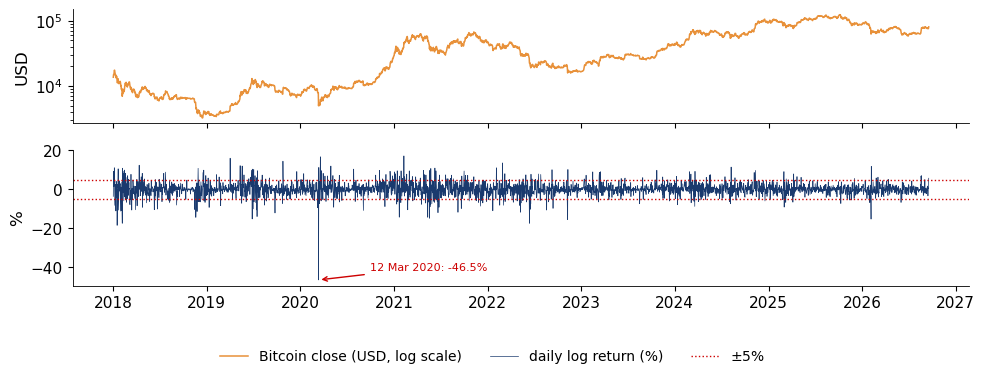

3,183 daily log returns, 01 Jan 2018 - 18 Sep 2026; sd 3.355%
Worst day 12 Mar 2020: -46.5%; best day 08 Feb 2021: +17.2%
Days with |r| > 5%: 340 (10.7%)
Sum of the daily log returns 174.3 = 100 ln(P_end / P_start) = 174.3


In [6]:
from scipy import stats
import statsmodels.api as sm


def close_cal(sym, start, end=END):
    # closes on the asset's own calendar: crypto every day; S&P 500 and gold Monday-Friday, repeated closes removed
    s = daily(sym, end).loc[start:]
    if not sym.endswith('.CC'):
        s = s[s.index.dayofweek < 5]
        s = s[s.diff() != 0]
    return s


def log_returns(sym, start='2017-12-31', first='2018-01-01', end=END):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1}), from `first`
    return (100 * np.log(close_cal(sym, start, end)).diff()).dropna().loc[first:]


# Bitcoin: from prices to daily log returns, 2018-2026
p_btc18 = close_cal('BTC-USD.CC', '2017-12-31')
r_btc18 = log_returns('BTC-USD.CC')
fig, ax = plt.subplots(2, 1, figsize=(10, 3.8), sharex=True, gridspec_kw={'height_ratios': [1, 1.2]})
ax[0].plot(p_btc18.loc['2018':].index, p_btc18.loc['2018':], color=BTC, lw=1.1, label='Bitcoin close (USD, log scale)')
ax[0].set_yscale('log'); ax[0].set_ylabel('USD')
ax[1].plot(r_btc18.index, r_btc18, color=BLUE, lw=0.5, label='daily log return (%)')
ax[1].axhline(5, color=RED, ls=':', lw=1, label=r'$\pm 5\%$'); ax[1].axhline(-5, color=RED, ls=':', lw=1)
wd = r_btc18.idxmin()
ax[1].annotate(f'{wd:%d %b %Y}: {r_btc18.min():.1f}%', xy=(wd, r_btc18.min()), xytext=(wd + pd.Timedelta(days=200), r_btc18.min() + 5),
               fontsize=8, color=RED, arrowprops=dict(arrowstyle='->', color=RED))
ax[1].set_ylabel('%')
legend_below(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l2_returns_path')

print(f'{len(r_btc18):,} daily log returns, {r_btc18.index[0]:%d %b %Y} - {r_btc18.index[-1]:%d %b %Y}; sd {r_btc18.std():.3f}%')
print(f'Worst day {r_btc18.idxmin():%d %b %Y}: {r_btc18.min():.1f}%; best day {r_btc18.idxmax():%d %b %Y}: {r_btc18.max():+.1f}%')
print(f'Days with |r| > 5%: {int((r_btc18.abs() > 5).sum())} ({100 * (r_btc18.abs() > 5).mean():.1f}%)')
print(f'Sum of the daily log returns {r_btc18.sum():.1f} = 100 ln(P_end / P_start) = {100 * np.log(p_btc18.iloc[-1] / p_btc18.iloc[0]):.1f}')

## 2. The Shape of Returns

### 2.1 Moments and the Jarque–Bera test

For $n$ daily returns, with mean $\bar r$ and standard deviation $s$, the sample skewness and excess kurtosis are

$$\hat S = \frac1n\sum_{t=1}^n \Big(\frac{r_t - \bar r}{s}\Big)^3, \qquad \hat K = \frac1n\sum_{t=1}^n \Big(\frac{r_t - \bar r}{s}\Big)^4 - 3.$$

For the Normal distribution both are 0. **Skewness** below 0 means a longer left tail (losses); **excess kurtosis**
above 0 means more extreme days than the Normal distribution predicts. The **Jarque–Bera (JB) test** combines them:

$$\mathrm{JB} = \frac{n}{6}\Big(\hat S^2 + \frac{\hat K^2}{4}\Big) \sim \chi^2_2 \text{ under } H_0\text{: Normal};$$

normality is rejected at 5% if JB exceeds 5.99. The table uses daily log returns from 1 January 2018 to
18 September 2026, each asset on its own calendar; annual volatility uses $A = 365$ for crypto and 252 otherwise.

In [7]:
A = {'Bitcoin': 365, 'Ethereum': 365, 'S&P 500': 252, 'Gold': 252}
rows = {}
for k, r in R.items():
    rows[k] = {'n': len(r), 'mean (%)': r.mean(), 'sd (%)': r.std(), 'annual vol. (%)': r.std() * np.sqrt(A[k]),
               'skewness': stats.skew(r), 'excess kurtosis': stats.kurtosis(r), 'worst day (%)': r.min(),
               'worst day': r.idxmin().date(), 'days |r| > 5% (%)': 100 * (r.abs() > 5).mean(),
               'JB': stats.jarque_bera(r).statistic}
T = pd.DataFrame(rows).T
print(T.to_string(float_format=lambda v: f'{v:,.3f}'))
print(f"\nBitcoin volatility / S&P 500 volatility (annual): {T.loc['Bitcoin', 'annual vol. (%)'] / T.loc['S&P 500', 'annual vol. (%)']:.1f}")
print(f"Bitcoin moves by more than 5% on one day in {100 / T.loc['Bitcoin', 'days |r| > 5% (%)']:.0f}")

             n mean (%) sd (%) annual vol. (%) skewness excess kurtosis worst day (%)   worst day days |r| > 5% (%)         JB
Bitcoin   3183    0.055  3.355          64.091   -0.945          14.825       -46.473  2020-03-12            10.682 29,620.197
Ethereum  3183    0.039  4.412          84.285   -0.825          11.063       -55.073  2020-03-12            17.782 16,592.906
S&P 500   2189    0.048  1.210          19.210   -0.646          14.922       -12.765  2020-03-16             0.640 20,462.241
Gold      2268    0.053  1.066          16.925   -0.548          10.249       -11.141  2026-01-30             0.309 10,040.940

Bitcoin volatility / S&P 500 volatility (annual): 3.3
Bitcoin moves by more than 5% on one day in 9


### 2.2 Worked example: Jarque–Bera for Bitcoin

The statistic splits into a skewness part $\hat S^2$ and a kurtosis part $\hat K^2/4$. The p-value is far below any
number a computer stores as a probability. With two degrees of freedom the $\chi^2_2$ tail is exactly
$P(\chi^2_2 > x) = e^{-x/2}$, so the cell prints the base-10 logarithm of the p-value, $-\mathrm{JB}/(2\ln 10)$.

In [8]:
r = R['Bitcoin']; n = len(r); S_, K_ = stats.skew(r), stats.kurtosis(r)
jb = n / 6 * (S_ ** 2 + K_ ** 2 / 4)
print(f'n = {n}, skewness = {S_:.3f}, excess kurtosis = {K_:.3f}')
print(f'JB = {n}/6 x ({S_ ** 2:.3f} + {K_ ** 2 / 4:.3f}) = {n / 6:.1f} x {S_ ** 2 + K_ ** 2 / 4:.3f} = {jb:,.0f}')
print(f'5% critical value of chi-square(2): {stats.chi2.ppf(0.95, 2):.2f}')
print(f'log10 of the p-value: {-jb / 2 / np.log(10):,.0f}, i.e. p-value = 10^({-jb / 2 / np.log(10):,.0f})')
print(f'Share of the statistic due to kurtosis: {K_ ** 2 / 4 / (S_ ** 2 + K_ ** 2 / 4):.1%}')

n = 3183, skewness = -0.945, excess kurtosis = 14.825
JB = 3183/6 x (0.892 + 54.942) = 530.5 x 55.834 = 29,620
5% critical value of chi-square(2): 5.99
log10 of the p-value: -6,432, i.e. p-value = 10^(-6,432)
Share of the statistic due to kurtosis: 98.4%


### 2.3 Fit of the Normal distribution

Left: the histogram of Bitcoin's daily returns against the Normal density with the same mean and standard
deviation. Middle and right: **QQ plots**, sorted standardised returns against the quantiles a Normal distribution
would give; Normal data lie on the red line. Returns beyond ±20% are drawn at ±20% in the histogram.

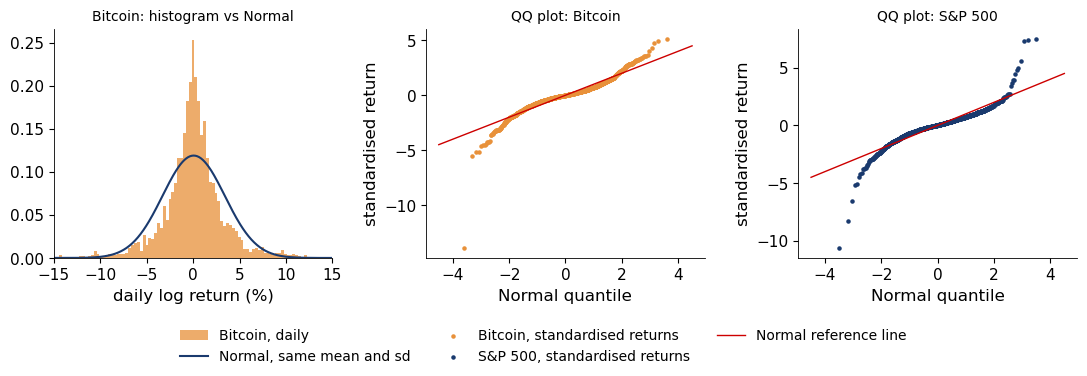

In [9]:
b = R['Bitcoin']
fig, ax = plt.subplots(1, 3, figsize=(11, 3.8))
xg = np.linspace(-20, 20, 400)
ax[0].hist(b.clip(-20, 20), bins=120, density=True, color=BTC, alpha=0.75, label='Bitcoin, daily')
ax[0].plot(xg, stats.norm.pdf(xg, b.mean(), b.std()), color=BLUE, lw=1.5, label='Normal, same mean and sd')
ax[0].set_xlim(-15, 15); ax[0].set_xlabel('daily log return (%)')
ax[0].set_title('Bitcoin: histogram vs Normal', fontsize=10)
for a_, k, col in [(ax[1], 'Bitcoin', BTC), (ax[2], 'S&P 500', BLUE)]:
    rr = R[k]; zz = np.sort(((rr - rr.mean()) / rr.std()).values)
    q = stats.norm.ppf((np.arange(1, len(zz) + 1) - 0.5) / len(zz))
    a_.scatter(q, zz, s=5, color=col, label=f'{k}, standardised returns')
    a_.plot([-4.5, 4.5], [-4.5, 4.5], color=RED, lw=1, label='Normal reference line' if k == 'S&P 500' else None)
    a_.set_xlabel('Normal quantile'); a_.set_ylabel('standardised return')
    a_.set_title(f'QQ plot: {k}', fontsize=10)
below(fig, ncol=3, bottom=0.14)
save_fig(fig, 'ba_l2_hist_qq')

### 2.4 Frequency of crashes

Standardise each return, $z_t = (r_t - \bar r)/s$, the number of standard deviations of the day, and compare the
frequency of large $|z_t|$ with the Normal probabilities.

In [10]:
z = (b - b.mean()) / b.std()
print(f'Normal distribution: P(|z| > 3) = {200 * stats.norm.sf(3):.2f}%, P(|z| > 4) = {200 * stats.norm.sf(4):.4f}%')
print(f'Expected number of days with |z| > 4 in {len(b):,} Normal days: {len(b) * 2 * stats.norm.sf(4):.1f}')
print(f'Bitcoin, 2018-2026: days with |z| > 3: {int((z.abs() > 3).sum())}; days with |z| > 4: {int((z.abs() > 4).sum())}')
print(f'Worst day: {b.idxmin():%d %B %Y}, log return {b.min():.1f}%, z = {z.min():.1f}; '
      f'as a simple return {100 * (np.exp(b.min() / 100) - 1):.1f}%')
pz = stats.norm.cdf(z.min())
print(f'Normal probability of a day at least this bad: {pz:.1e}, i.e. once in {1 / pz:.1e} days')

Normal distribution: P(|z| > 3) = 0.27%, P(|z| > 4) = 0.0063%
Expected number of days with |z| > 4 in 3,183 Normal days: 0.2
Bitcoin, 2018-2026: days with |z| > 3: 59; days with |z| > 4: 17
Worst day: 12 March 2020, log return -46.5%, z = -13.9; as a simple return -37.2%
Normal probability of a day at least this bad: 4.8e-44, i.e. once in 2.1e+43 days


### 2.5 Crash days: observed against the Normal distribution

For each threshold $k = 2, \dots, 6$, the number of days with $|z_t| > k$ in 2018–2026, against the number a Normal
distribution would give, $n \times P(|z| > k) = 2n\,[1 - \Phi(k)]$. Bitcoin and the S&P 500, each on its own calendar;
log scale, because the expected numbers fall from about a hundred to one in a million.

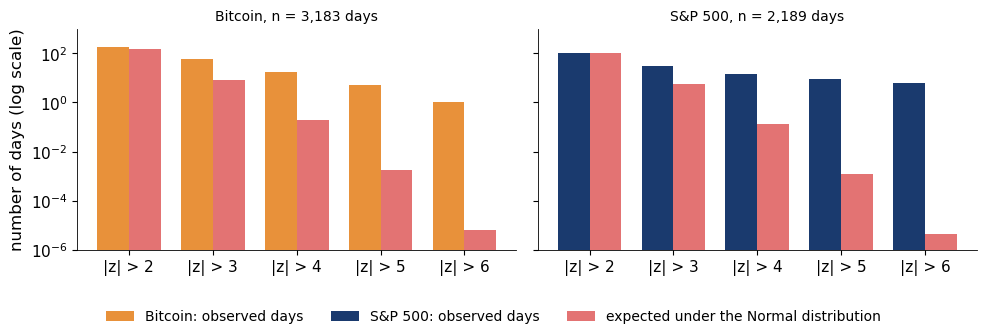

Bitcoin (n = 3,183)
   observed   Normal       ratio
2       185  144.827       1.277
3        59    8.593       6.866
4        17    0.202      84.317
5         5    0.002    2739.990
6         1    0.000  159220.027
S&P 500 (n = 2,189)
   observed  Normal        ratio
2        99  99.600        0.994
3        30   5.910        5.076
4        15   0.139      108.181
5         9   0.001     7171.540
6         6   0.000  1389120.181


In [11]:
# days beyond k standard deviations: observed against the Normal distribution, 2018-2026
K = [2, 3, 4, 5, 6]
crash = {}
for nm, sym in [('Bitcoin', 'BTC-USD.CC'), ('S&P 500', 'GSPC.INDX')]:
    r_ = log_returns(sym); z_ = (r_ - r_.mean()) / r_.std()
    crash[nm] = pd.DataFrame({'observed': [int((z_.abs() > k).sum()) for k in K],
                              'Normal': [len(r_) * 2 * stats.norm.sf(k) for k in K]}, index=K)
    crash[nm].attrs['n'] = len(r_)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
w_ = 0.38
for a_, (nm, col) in zip(ax, [('Bitcoin', BTC), ('S&P 500', BLUE)]):
    t_ = crash[nm]; x_ = np.arange(len(K))
    a_.bar(x_ - w_ / 2, t_['observed'].clip(lower=0.5), w_, color=col, label=f'{nm}: observed days')
    a_.bar(x_ + w_ / 2, t_['Normal'], w_, color=RED, alpha=0.55, label=('expected under the Normal distribution' if nm == 'S&P 500' else None))
    a_.set_xticks(x_); a_.set_xticklabels([f'|z| > {k}' for k in K]); a_.set_yscale('log'); a_.set_ylim(1e-6, 1e3)
    a_.set_title(f'{nm}, n = {t_.attrs["n"]:,} days', fontsize=10)
ax[0].set_ylabel('number of days (log scale)')
legend_below(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l2_crash_counts')
for nm, t_ in crash.items():
    print(nm, f'(n = {t_.attrs["n"]:,})')
    print((t_.assign(ratio=t_['observed'] / t_['Normal'])).round(3).to_string())

### 2.6 Worked example: expected crash days under the Normal

The computation of the chart for $k = 3$ and $k = 4$, and the waiting time between two days beyond 4 standard
deviations: $1/P(|z| > 4)$ days under the Normal, $n/(\text{observed days})$ in the data.

In [12]:
# worked example: expected number of days beyond 3 and 4 standard deviations under the Normal distribution
n_ = crash['Bitcoin'].attrs['n']
for k in [3, 4]:
    p_ = 2 * stats.norm.sf(k)
    print(f'P(|z| > {k}) = 2 x {stats.norm.sf(k):.3e} = {p_:.3e}; expected days = {n_:,} x {p_:.3e} = {n_ * p_:.2f}; '
          f'observed (Bitcoin) {crash["Bitcoin"].loc[k, "observed"]}, ratio {crash["Bitcoin"].loc[k, "observed"] / (n_ * p_):.0f}')
print(f'Days between two |z| > 4 days: Normal {1 / (2 * stats.norm.sf(4)):,.0f} days ({1 / (2 * stats.norm.sf(4)) / 365:.0f} years); '
      f'observed {n_ / crash["Bitcoin"].loc[4, "observed"]:.0f} days')

P(|z| > 3) = 2 x 1.350e-03 = 2.700e-03; expected days = 3,183 x 2.700e-03 = 8.59; observed (Bitcoin) 59, ratio 7
P(|z| > 4) = 2 x 3.167e-05 = 6.334e-05; expected days = 3,183 x 6.334e-05 = 0.20; observed (Bitcoin) 17, ratio 84
Days between two |z| > 4 days: Normal 15,787 days (43 years); observed 187 days


## 3. Volatility and Correlation

### 3.1 Volatility through time

**Rolling volatility** on the last $w$ returns, annualised:

$$\hat\sigma_{a,t} = \sqrt{A}\,\sqrt{\frac{1}{w-1}\sum_{j=0}^{w-1}\big(r_{t-j} - \bar r_t\big)^2}, \qquad \bar r_t = \frac1w\sum_{j=0}^{w-1} r_{t-j}.$$

About one month: $w = 30$ daily returns and $A = 365$ for crypto, $w = 21$ and $A = 252$ for the S&P 500. Sample
from 1 January 2016.

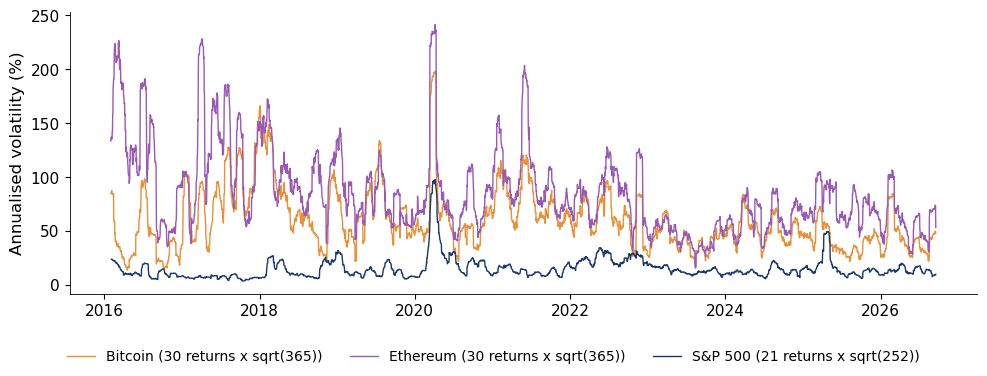

Bitcoin  : median  53.8%, maximum 198.0% on 06 Apr 2020, last  47.2%
Ethereum : median  77.3%, maximum 241.4% on 06 Apr 2020, last  53.2%
S&P 500  : median  12.3%, maximum  97.6% on 06 Apr 2020, last   9.6%
Share of common days with Bitcoin volatility below S&P 500 volatility: 0.1%


In [13]:
vol = {}
fig, ax = plt.subplots(figsize=(10, 3.8))
for k, w, ppy in [('btc', 30, 365), ('eth', 30, 365), ('sp500', 21, 252)]:
    v = returns(k, '2016-01-01').rolling(w).std() * np.sqrt(ppy)
    vol[k] = v.dropna()
    ax.plot(v.index, v.values, color=COL[k], lw=1.0, label=f'{NAME[k]} ({w} returns x sqrt({ppy}))')
ax.set_ylabel('Annualised volatility (%)')
below(fig, ncol=3, bottom=0.10)
save_fig(fig, 'ba_l2_rolling_vol')

for k, v in vol.items():
    print(f'{NAME[k]:9s}: median {v.median():5.1f}%, maximum {v.max():5.1f}% on {v.idxmax():%d %b %Y}, '
          f'last {v.iloc[-1]:5.1f}%')
j = pd.concat([vol['btc'], vol['sp500']], axis=1).dropna()
print(f'Share of common days with Bitcoin volatility below S&P 500 volatility: {100 * (j.iloc[:, 0] < j.iloc[:, 1]).mean():.1f}%')

### 3.2 Autocorrelation and the Ljung–Box test

The sample autocorrelation at lag $k$ and the Ljung–Box statistic of the first $m$ autocorrelations are

$$\hat\rho(k) = \frac{\sum_{t=k+1}^{n}(r_t - \bar r)(r_{t-k} - \bar r)}{\sum_{t=1}^{n}(r_t - \bar r)^2}, \qquad
Q(m) = n(n+2)\sum_{k=1}^{m}\frac{\hat\rho(k)^2}{n-k} \sim \chi^2_m \text{ under } H_0\text{: no autocorrelation}.$$

Under independence $\hat\rho(k)$ lies within $\pm 1.96/\sqrt n$ with probability 95%. The autocorrelation function
(ACF) of $r_t$ asks whether the direction of the move is predictable; the ACF of $r_t^2$ asks whether its size is.
Bitcoin, daily, 17 September 2014 to 18 September 2026.

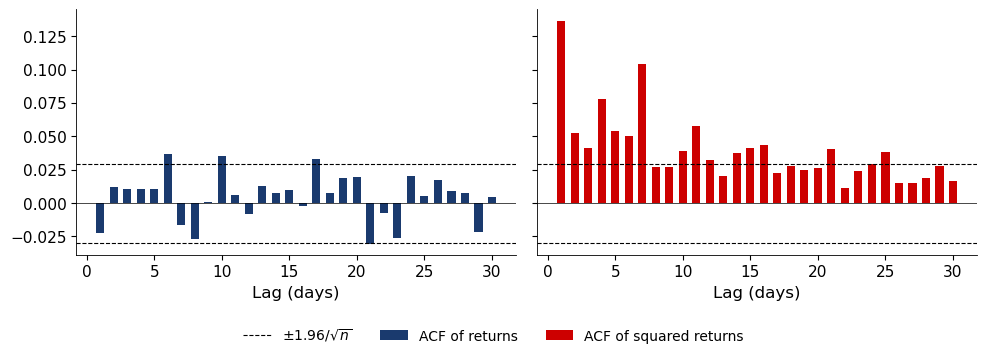

Bitcoin: n = 4,384 daily returns; 95% band of pure noise: +-0.030
Lag-1 autocorrelation: returns -0.022, squared returns 0.137
Ljung-Box Q(10) for returns r_t: 20.2 (p-value 0.0276)
Ljung-Box Q(10) for squared returns r_t^2: 212.7 (p-value 3.52e-40)
5% critical value of chi-square(10): 18.3


In [14]:
def acf(x, nlags):
    e = np.asarray(x, float) - np.mean(x)
    return np.array([np.sum(e[k:] * e[:-k]) for k in range(1, nlags + 1)]) / np.sum(e ** 2)


def ljung_box(x, m=10):
    n = len(x); rho = acf(x, m)
    q = n * (n + 2) * np.sum(rho ** 2 / (n - np.arange(1, m + 1)))
    return q, stats.chi2.sf(q, m)


rb = returns('btc').values
n = len(rb); band = 1.96 / np.sqrt(n)
a1, a2 = acf(rb, 30), acf(rb ** 2, 30)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
lags = np.arange(1, 31)
for ax, a, c, lab in [(axes[0], a1, BLUE, 'ACF of returns'), (axes[1], a2, RED, 'ACF of squared returns')]:
    ax.bar(lags, a, color=c, width=0.6, label=lab)
    ax.axhline(band, color='black', lw=0.8, ls='--'); ax.axhline(-band, color='black', lw=0.8, ls='--')
    ax.axhline(0, color='black', lw=0.5); ax.set_xlabel('Lag (days)')
axes[0].plot([], [], color='black', ls='--', lw=0.8, label=r'$\pm 1.96/\sqrt{n}$')
below(fig, ncol=3, bottom=0.10)
save_fig(fig, 'ba_l2_acf')

print(f'Bitcoin: n = {n:,} daily returns; 95% band of pure noise: +-{band:.3f}')
print(f'Lag-1 autocorrelation: returns {a1[0]:.3f}, squared returns {a2[0]:.3f}')
for lab, x in [('returns r_t', rb), ('squared returns r_t^2', rb ** 2)]:
    q, pv = ljung_box(x)
    print(f'Ljung-Box Q(10) for {lab}: {q:.1f} (p-value {pv:.3g})')
print(f'5% critical value of chi-square(10): {stats.chi2.ppf(0.95, 10):.1f}')

### 3.3 Worked example: Ljung–Box with two lags

$Q(2) = n(n+2)\big[\hat\rho(1)^2/(n-1) + \hat\rho(2)^2/(n-2)\big]$ for Bitcoin's returns and squared returns, term by
term, with the 5% critical value of $\chi^2_2$ and the 95% band of one autocorrelation, $\pm 1.96/\sqrt n$.

In [15]:
# worked example: Ljung-Box with m = 2 lags, Bitcoin since 17 September 2014
r_lb = (100 * np.log(close_cal('BTC-USD.CC', '2014-09-17'))).diff().dropna().values
n_lb = len(r_lb)


def acf_k(x, k):
    e = np.asarray(x, float) - np.mean(x)
    return np.sum(e[k:] * e[:-k]) / np.sum(e ** 2)


for lab, x_ in [('r_t', r_lb), ('r_t^2', r_lb ** 2)]:
    r1_, r2_ = acf_k(x_, 1), acf_k(x_, 2)
    t1, t2 = r1_ ** 2 / (n_lb - 1), r2_ ** 2 / (n_lb - 2)
    q2 = n_lb * (n_lb + 2) * (t1 + t2)
    print(f'{lab}: rho(1) = {r1_:.4f}, rho(2) = {r2_:.4f}; Q(2) = {n_lb} x {n_lb + 2} x ({r1_ ** 2:.6f}/{n_lb - 1} + {r2_ ** 2:.6f}/{n_lb - 2}) '
          f'= {q2:.2f}; p-value {stats.chi2.sf(q2, 2):.3g}')
print(f'n = {n_lb:,}; 5% critical value of chi-square(2): {stats.chi2.ppf(0.95, 2):.2f}; 95% band of one autocorrelation +-{1.96 / np.sqrt(n_lb):.4f}')

r_t: rho(1) = -0.0223, rho(2) = 0.0121; Q(2) = 4384 x 4386 x (0.000498/4383 + 0.000147/4382) = 2.83; p-value 0.243
r_t^2: rho(1) = 0.1367, rho(2) = 0.0527; Q(2) = 4384 x 4386 x (0.018684/4383 + 0.002778/4382) = 94.16; p-value 3.58e-21
n = 4,384; 5% critical value of chi-square(2): 5.99; 95% band of one autocorrelation +-0.0296


### 3.4 Absolute returns after calm and turbulent days

A direct look at volatility clustering: the days of 2018–2026 are sorted into five groups of equal size (quintiles)
by yesterday's absolute return, and the bars show today's mean absolute return in each group. Under independence all
five bars would be at the dashed line, the mean over all days.

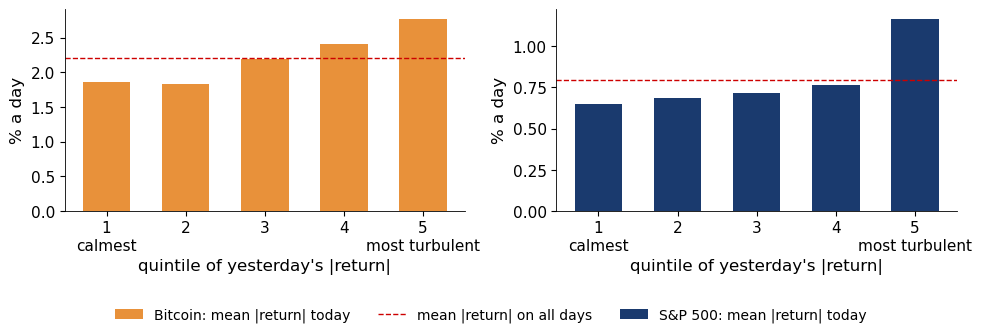

Bitcoin: mean |r_t| by quintile of |r_(t-1)|: 1.86, 1.83, 2.19, 2.40, 2.77 (all days 2.21); most turbulent / calmest = 1.49
S&P 500: mean |r_t| by quintile of |r_(t-1)|: 0.65, 0.68, 0.72, 0.76, 1.17 (all days 0.79); most turbulent / calmest = 1.80


In [16]:
# calm follows calm: mean |r_t| by quintile of |r_(t-1)|, 2018-2026
calm = {}
for nm, sym in [('Bitcoin', 'BTC-USD.CC'), ('S&P 500', 'GSPC.INDX')]:
    a_ = log_returns(sym).abs()
    q_ = pd.qcut(a_.shift(1), 5, labels=False)
    calm[nm] = (a_.groupby(q_).mean(), a_.mean())

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for a_, (nm, col) in zip(ax, [('Bitcoin', BTC), ('S&P 500', BLUE)]):
    g_, m_ = calm[nm]
    a_.bar(np.arange(1, 6), g_.values, color=col, width=0.6, label=f'{nm}: mean |return| today')
    a_.axhline(m_, color=RED, ls='--', lw=1, label=('mean |return| on all days' if nm == 'S&P 500' else None))
    a_.set_xticks(range(1, 6)); a_.set_xticklabels(['1\ncalmest', '2', '3', '4', '5\nmost turbulent'])
    a_.set_xlabel('quintile of yesterday\'s |return|'); a_.set_ylabel('% a day')
legend_below(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l2_calm')
for nm, (g_, m_) in calm.items():
    print(f'{nm}: mean |r_t| by quintile of |r_(t-1)|:', ', '.join(f'{v:.2f}' for v in g_.values),
          f'(all days {m_:.2f}); most turbulent / calmest = {g_.iloc[-1] / g_.iloc[0]:.2f}')

### 3.5 Correlation of Bitcoin with equities

Pearson correlation of daily returns on rolling windows of 250 common days, about one year of equity trading:

$$\hat\rho_{xy,t} = \frac{\sum_{j=0}^{w-1}(x_{t-j} - \bar x_t)(y_{t-j} - \bar y_t)}{\sqrt{\sum_{j=0}^{w-1}(x_{t-j} - \bar x_t)^2}\,\sqrt{\sum_{j=0}^{w-1}(y_{t-j} - \bar y_t)^2}}.$$

Prices are joined on common days first and returns computed after, so that Monday's Bitcoin return covers Friday to
Monday, like the equity return. Dashed vertical lines mark the COVID-19 crash, the collapse of Terra/Luna, the
bankruptcy of FTX and the first trading day of the spot Bitcoin exchange-traded funds (ETFs).

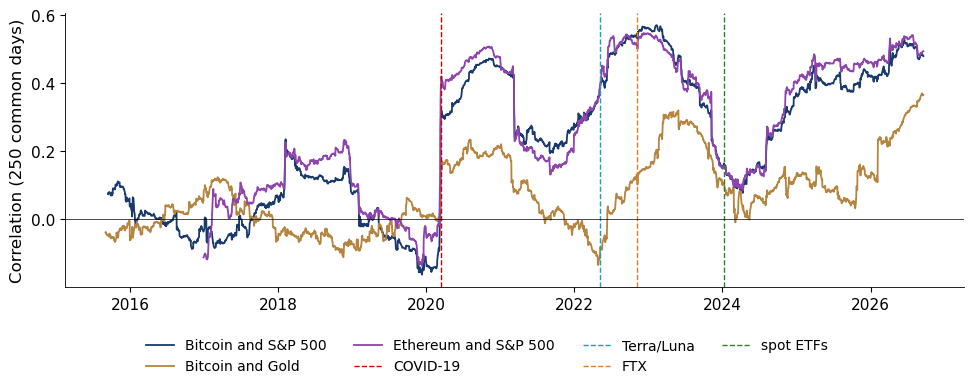

Bitcoin and S&P 500, 3,017 common days
Correlation before 2020: 0.02; from 2020: 0.39
Highest rolling correlation: 0.57 (09 February 2023); last: 0.48


In [17]:
EVENTS = {'COVID-19': ('2020-03-12', RED), 'Terra/Luna': ('2022-05-09', TEAL), 'FTX': ('2022-11-08', ORANGE),
          'spot ETFs': ('2024-01-11', GREEN)}
fig, ax = plt.subplots(figsize=(10, 3.9))
corr = {}
for (a, bb), c in zip([('btc', 'sp500'), ('btc', 'gold'), ('eth', 'sp500')], [BLUE, GOLD, PURPLE]):
    J = joint_returns(a, bb)
    rc = J[a].rolling(250).corr(J[bb]).dropna()
    corr[(a, bb)] = (J, rc)
    ax.plot(rc.index, rc.values, color=c, lw=1.3, label=f'{NAME[a]} and {NAME[bb]}')
for lab, (d, c) in EVENTS.items():
    ax.axvline(pd.Timestamp(d), color=c, lw=1.0, ls='--', label=lab)
ax.axhline(0, color='black', lw=0.5)
ax.set_ylabel('Correlation (250 common days)')
below(fig, ncol=4, bottom=0.14)
save_fig(fig, 'ba_l2_rolling_corr')

J, rc = corr[('btc', 'sp500')]
print(f'Bitcoin and S&P 500, {len(J):,} common days')
print(f"Correlation before 2020: {J.loc[:'2019-12-31', 'btc'].corr(J.loc[:'2019-12-31', 'sp500']):.2f}; "
      f"from 2020: {J.loc['2020':, 'btc'].corr(J.loc['2020':, 'sp500']):.2f}")
print(f'Highest rolling correlation: {rc.max():.2f} ({rc.idxmax():%d %B %Y}); last: {rc.iloc[-1]:.2f}')

## 4. Market Efficiency

### 4.1 Variance-ratio tests

In a **weak-form efficient** market past prices do not help to predict future returns. The **variance ratio** (VR)
compares the variance of $q$-day returns with $q$ times the daily variance:

$$\mathrm{VR}(q) = \frac{\mathrm{Var}(r_t + r_{t-1} + \dots + r_{t-q+1})}{q\,\mathrm{Var}(r_t)}.$$

Under a random walk $\mathrm{VR} = 1$; $\mathrm{VR} > 1$ indicates trends (momentum), $\mathrm{VR} < 1$ reversals
(mean reversion). The test statistic robust to volatility clustering is

$$Z^*(q) = \frac{\widehat{\mathrm{VR}}(q) - 1}{\sqrt{\hat\theta^*(q)}} \approx N(0, 1), \qquad
\hat\theta^*(q) = \sum_{j=1}^{q-1}\Big[\frac{2(q-j)}{q}\Big]^2\hat\delta_j, \qquad
\hat\delta_j = \frac{\sum_{t=j+1}^{n}(r_t - \bar r)^2(r_{t-j} - \bar r)^2}{\Big[\sum_{t=1}^{n}(r_t - \bar r)^2\Big]^2},$$

and the random walk is rejected at 5% if $|Z^*| > 1.96$. $\hat\delta_j$ is the variance of the lag-$j$ autocorrelation
when volatility changes over time. The estimator uses overlapping $q$-day sums. Sample: full
history of each asset since 2014 (Ethereum since 2016) to 18 September 2026, and three sub-periods.

In [18]:
def variance_ratio(x, q):
    x = np.asarray(x, float); T = len(x); mu = x.mean(); e = x - mu
    var_a = np.sum(e ** 2) / (T - 1)
    agg = np.convolve(x, np.ones(q), mode='valid') - q * mu
    m = q * (T - q + 1) * (1 - q / T)
    vr = (np.sum(agg ** 2) / m) / var_a
    den = np.sum(e ** 2) ** 2
    theta = sum((2 * (q - j) / q) ** 2 * T * np.sum(e[j:] ** 2 * e[:-j] ** 2) / den for j in range(1, q))
    zs = (vr - 1) / np.sqrt(theta / T)
    return vr, zs, 2 * stats.norm.sf(abs(zs))


rows = {}
for k in ['btc', 'eth', 'sp500']:
    x = returns(k).values
    v = {q: variance_ratio(x, q) for q in (2, 5, 10)}
    rows[NAME[k]] = {'n': len(x), 'VR(2)': v[2][0], 'VR(5)': v[5][0], 'VR(10)': v[10][0],
                     'Z*(5)': v[5][1], 'p-value of Z*(5)': v[5][2]}
print('Whole sample')
VT = pd.DataFrame(rows).T; VT['n'] = VT['n'].astype(int)
print(VT.round(3).to_string())

SUB = [('2014-09-17', '2017-12-31'), ('2018-01-01', '2021-12-31'), ('2022-01-01', END)]
rows = []
for k in ['btc', 'eth', 'sp500']:
    for a, bnd in SUB:
        a = max(a, START[k])
        x = returns(k, a, bnd).values
        vr, zs, pv = variance_ratio(x, 5)
        rows.append({'asset': NAME[k], 'period': f'{a[:4]}-{bnd[:4]}', 'n': len(x), 'VR(5)': vr, 'Z*(5)': zs, 'p-value': pv})
print('\nSub-periods')
print(pd.DataFrame(rows).set_index(['asset', 'period']).round(3).to_string())

Whole sample
             n  VR(2)  VR(5)  VR(10)  Z*(5)  p-value of Z*(5)
Bitcoin   4384  0.977  0.991   1.027 -0.185             0.853
Ethereum  3913  0.988  1.067   1.137  1.174             0.241
S&P 500   3017  0.875  0.849   0.813 -1.280             0.201



Sub-periods
                       n  VR(5)  Z*(5)  p-value
asset    period                                
Bitcoin  2014-2017  1201  0.975 -0.234    0.815
         2018-2021  1460  0.981 -0.252    0.801
         2022-2026  1721  1.013  0.181    0.856
Ethereum 2016-2017   730  1.127  1.031    0.303
         2018-2021  1460  0.997 -0.037    0.971
         2022-2026  1721  1.014  0.197    0.844
S&P 500  2014-2017   827  0.916 -0.680    0.497
         2018-2021  1007  0.784 -0.954    0.340
         2022-2026  1181  0.918 -0.849    0.396


### 4.2 Variance ratios by sub-period

The robust $Z^*(5)$ of Section 4.1 in the three sub-periods 2014–2017 (Ethereum from 2016), 2018–2021 and
2022–2026, as bars against the 5% critical values $\pm 1.96$.

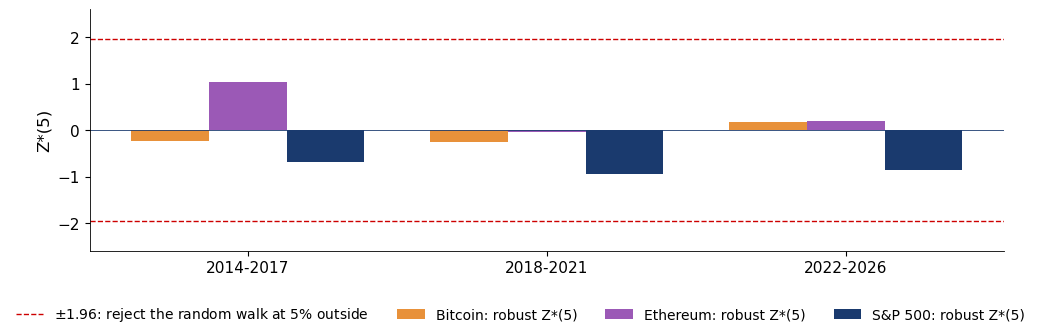

   asset    period      start    n  VR(5)  Z*(5)
 Bitcoin 2014-2017 2014-09-17 1201  0.975 -0.234
 Bitcoin 2018-2021 2018-01-01 1460  0.981 -0.252
 Bitcoin 2022-2026 2022-01-01 1721  1.013  0.181
Ethereum 2014-2017 2016-01-01  730  1.127  1.031
Ethereum 2018-2021 2018-01-01 1460  0.997 -0.037
Ethereum 2022-2026 2022-01-01 1721  1.014  0.197
 S&P 500 2014-2017 2014-09-17  827  0.916 -0.680
 S&P 500 2018-2021 2018-01-01 1007  0.784 -0.954
 S&P 500 2022-2026 2022-01-01 1181  0.918 -0.849


In [19]:
# robust variance-ratio statistic Z*(5) by sub-period
def vr_robust(x, q):
    x = np.asarray(x, float); T = len(x); mu = x.mean(); e = x - mu
    var_a = np.sum(e ** 2) / (T - 1)
    agg = np.convolve(x, np.ones(q), mode='valid') - q * mu
    m = q * (T - q + 1) * (1 - q / T)
    vr = (np.sum(agg ** 2) / m) / var_a
    den = np.sum(e ** 2) ** 2
    theta = sum((2 * (q - j) / q) ** 2 * T * np.sum(e[j:] ** 2 * e[:-j] ** 2) / den for j in range(1, q))
    return vr, (vr - 1) / np.sqrt(theta / T)


PERIODS = [('2014-09-17', '2017-12-31'), ('2018-01-01', '2021-12-31'), ('2022-01-01', END)]
FIRST = {'Bitcoin': '2014-09-17', 'Ethereum': '2016-01-01', 'S&P 500': '2014-09-17'}
vrp = []
for nm, sym in [('Bitcoin', 'BTC-USD.CC'), ('Ethereum', 'ETH-USD.CC'), ('S&P 500', 'GSPC.INDX')]:
    for a0, e_ in PERIODS:
        a = max(a0, FIRST[nm])                            # Ethereum starts in 2016
        x_ = (100 * np.log(close_cal(sym, a, e_))).diff().dropna().values
        vr_, zs_ = vr_robust(x_, 5)
        vrp.append({'asset': nm, 'period': f'{a0[:4]}-{e_[:4]}', 'start': a, 'n': len(x_), 'VR(5)': vr_, 'Z*(5)': zs_})
vrp = pd.DataFrame(vrp)

fig, ax = plt.subplots(figsize=(10, 3.4))
labs = vrp['period'].unique(); x_ = np.arange(len(labs)); w_ = 0.26
for i, (nm, col) in enumerate([('Bitcoin', BTC), ('Ethereum', ETH), ('S&P 500', BLUE)]):
    v_ = vrp[vrp['asset'] == nm].set_index('period')['Z*(5)'].reindex(labs)
    ax.bar(x_ + (i - 1) * w_, v_.values, w_, color=col, label=f'{nm}: robust Z*(5)')
ax.axhline(1.96, color=RED, ls='--', lw=1, label=r'$\pm 1.96$: reject the random walk at 5% outside'); ax.axhline(-1.96, color=RED, ls='--', lw=1)
ax.axhline(0, color=BLUE, lw=0.6)
ax.set_xticks(x_); ax.set_xticklabels(labs); ax.set_ylabel('Z*(5)'); ax.set_ylim(-2.6, 2.6)
legend_below(fig, ncol=4, bottom=0.12)
save_fig(fig, 'ba_l2_vr_periods')
print(vrp.round(3).to_string(index=False))

### 4.3 Efficiency through time

The robust $Z^*(5)$ on windows of 500 daily returns, moving forward 21 returns at a time. Dashed lines: $\pm 1.96$.

Bitcoin  : 185 windows; share with |Z*(5)| > 1.96: 0.0%; Z*(5) from -1.45 to 1.08
Ethereum : 163 windows; share with |Z*(5)| > 1.96: 0.0%; Z*(5) from -1.39 to 1.26


S&P 500  : 120 windows; share with |Z*(5)| > 1.96: 0.0%; Z*(5) from -1.74 to 0.09


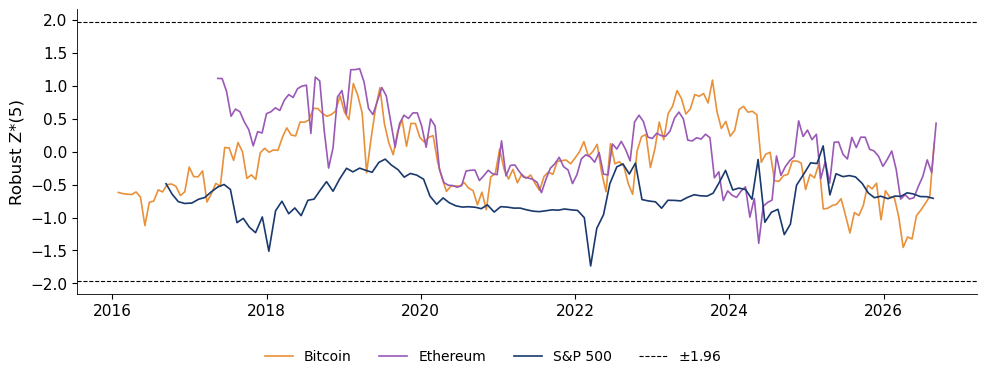

In [20]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for k in ['btc', 'eth', 'sp500']:
    r_ = returns(k); x = r_.values
    rows = [(r_.index[e - 1],) + variance_ratio(x[e - 500:e], 5)[:2] for e in range(500, len(x) + 1, 21)]
    d = pd.DataFrame(rows, columns=['date', 'vr', 'zs']).set_index('date')
    ax.plot(d.index, d['zs'], color=COL[k], lw=1.2, label=NAME[k])
    print(f'{NAME[k]:9s}: {len(d)} windows; share with |Z*(5)| > 1.96: {100 * (d["zs"].abs() > 1.96).mean():.1f}%; '
          f'Z*(5) from {d["zs"].min():.2f} to {d["zs"].max():.2f}')
ax.axhline(1.96, color='black', lw=0.8, ls='--', label=r'$\pm 1.96$'); ax.axhline(-1.96, color='black', lw=0.8, ls='--')
ax.set_ylabel('Robust Z*(5)')
below(fig, ncol=4, bottom=0.10)
save_fig(fig, 'ba_l2_rolling_vr')

## 5. Bubbles, Crashes and Network Value

### 5.1 Drawdowns

The **drawdown** on day $t$ is $D_t = P_t/\max_{s \le t} P_s - 1$, the loss from the last record high. The
**maximum drawdown** is the deepest fall; the **time under water** is the number of days until a new record. A loss
of $d$ needs a gain of $d/(1-d)$ to recover. Daily closes since 1 January 2016.

A loss of 50.0% needs a gain of 100% to recover
A loss of 75.0% needs a gain of 300% to recover
A loss of 83.4% needs a gain of 502% to recover


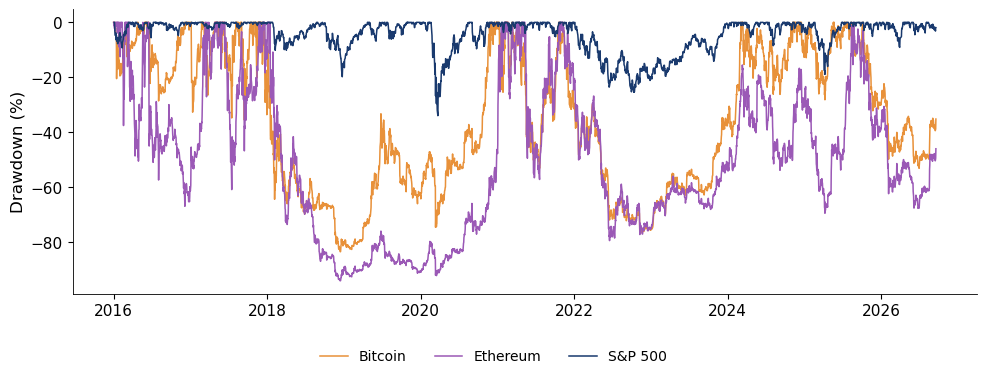

Bitcoin  : maximum drawdown -83.4% (15 Dec 2018); days more than 10% below the record: 76%
Ethereum : maximum drawdown -94.0% (14 Dec 2018); days more than 10% below the record: 90%
S&P 500  : maximum drawdown -33.9% (23 Mar 2020); days more than 10% below the record: 16%


In [21]:
for d in [0.50, 0.75, 0.834]:
    print(f'A loss of {100 * d:.1f}% needs a gain of {100 * d / (1 - d):.0f}% to recover')

dd = {}
fig, ax = plt.subplots(figsize=(10, 3.8))
for k in ['btc', 'eth', 'sp500']:
    p_ = close(k, '2016-01-01')
    dd[k] = 100 * (p_ / p_.cummax() - 1)
    ax.plot(dd[k].index, dd[k].values, color=COL[k], lw=1.1, label=NAME[k])
ax.set_ylabel('Drawdown (%)')
below(fig, ncol=3, bottom=0.10)
save_fig(fig, 'ba_l2_drawdowns')
for k, v in dd.items():
    print(f'{NAME[k]:9s}: maximum drawdown {v.min():.1f}% ({v.idxmin():%d %b %Y}); '
          f'days more than 10% below the record: {100 * (v < -10).mean():.0f}%')

### 5.2 The gain needed to recover

A loss of $d$ needs a gain of $d/(1-d)$ to return to the record. The curve, on a log scale, with the maximum drawdowns
of the S&P 500, Bitcoin and Ethereum since 2016; the dotted line is the gain equal to the loss that intuition
suggests.

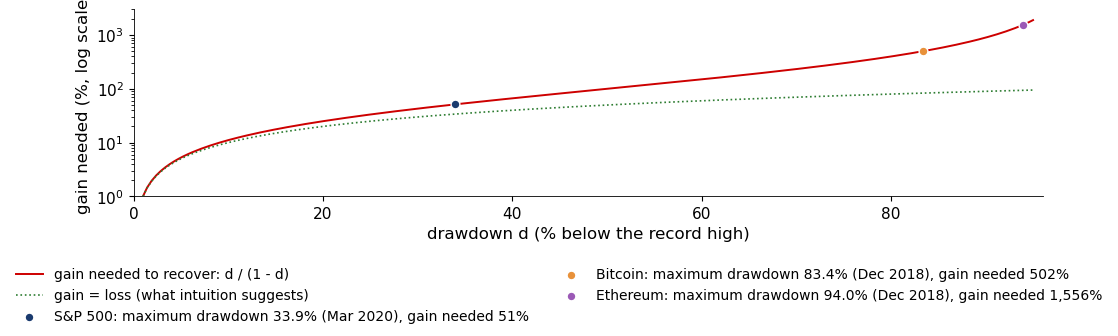

S&P 500: maximum drawdown 33.9% on 23 Mar 2020; gain needed 51%
Bitcoin: maximum drawdown 83.4% on 15 Dec 2018; gain needed 502%
Ethereum: maximum drawdown 94.0% on 14 Dec 2018; gain needed 1556%


In [22]:
# the gain needed to recover a drawdown d is d / (1 - d); maximum drawdowns since 2016
d_grid = np.linspace(0, 0.95, 200)
mdd = {}
for nm, sym in [('S&P 500', 'GSPC.INDX'), ('Bitcoin', 'BTC-USD.CC'), ('Ethereum', 'ETH-USD.CC')]:
    p_ = close_cal(sym, '2016-01-01')
    dd_ = p_ / p_.cummax() - 1
    mdd[nm] = (-dd_.min(), dd_.idxmin())

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(100 * d_grid, 100 * d_grid / (1 - d_grid), color=RED, lw=1.4, label='gain needed to recover: d / (1 - d)')
ax.plot(100 * d_grid, 100 * d_grid, color=GREEN, ls=':', lw=1.2, label='gain = loss (what intuition suggests)')
for nm, col in [('S&P 500', BLUE), ('Bitcoin', BTC), ('Ethereum', ETH)]:
    d_, t_ = mdd[nm]
    ax.scatter([100 * d_], [100 * d_ / (1 - d_)], color=col, s=40, zorder=5, edgecolor='white',
               label=f'{nm}: maximum drawdown {100 * d_:.1f}% ({t_:%b %Y}), gain needed {100 * d_ / (1 - d_):,.0f}%')
ax.set_yscale('log'); ax.set_ylim(1, 3000); ax.set_xlim(0, 96)
ax.set_xlabel('drawdown d (% below the record high)'); ax.set_ylabel('gain needed (%, log scale)')
legend_below(fig, ncol=2, bottom=0.22)
save_fig(fig, 'ba_l2_recovery')
for nm, (d_, t_) in mdd.items():
    print(f'{nm}: maximum drawdown {100 * d_:.1f}% on {t_:%d %b %Y}; gain needed {100 * d_ / (1 - d_):.0f}%')

### 5.3 Worked example: a drawdown and its recovery

The Bitcoin drawdown from the record of November 2021: depth, gain needed, days under water, and the growth rate the
recovery actually took, against a steady 50% a year.

In [23]:
# worked example: the Bitcoin drawdown of November 2021 - November 2022 and its recovery
pb_ = close_cal('BTC-USD.CC', '2014-09-17')
pk_ = pb_.loc['2021-01-01':'2022-01-01'].idxmax(); peak_ = pb_[pk_]
tr_ = pb_.loc[pk_:'2023-12-31'].idxmin(); trough_ = pb_[tr_]
rec_ = pb_.loc[tr_:][pb_.loc[tr_:] > peak_].index[0]
d_ = 1 - trough_ / peak_
print(f'Peak {pk_:%d %b %Y}: {peak_:,.0f} USD; trough {tr_:%d %b %Y}: {trough_:,.0f} USD')
print(f'Drawdown d = 1 - {trough_:,.0f} / {peak_:,.0f} = {100 * d_:.1f}%')
print(f'Gain needed d / (1 - d) = {d_:.3f} / {1 - d_:.3f} = {100 * d_ / (1 - d_):.0f}%  (= {peak_:,.0f} / {trough_:,.0f} - 1)')
print(f'New record {rec_:%d %b %Y}: {(rec_ - pk_).days} days after the peak, {(rec_ - tr_).days} days after the trough')
yrs = (rec_ - tr_).days / 365
print(f'Growth from the trough to the record: ({peak_:,.0f} / {trough_:,.0f})^(1/{yrs:.2f}) - 1 = {100 * ((peak_ / trough_) ** (1 / yrs) - 1):.0f}% a year')
print(f'Time to recover at a steady 50% a year: ln({peak_ / trough_:.2f}) / ln(1.5) = {np.log(peak_ / trough_) / np.log(1.5):.1f} years')

Peak 08 Nov 2021: 67,567 USD; trough 21 Nov 2022: 15,787 USD
Drawdown d = 1 - 15,787 / 67,567 = 76.6%
Gain needed d / (1 - d) = 0.766 / 0.234 = 328%  (= 67,567 / 15,787 - 1)
New record 04 Mar 2024: 847 days after the peak, 469 days after the trough
Growth from the trough to the record: (67,567 / 15,787)^(1/1.28) - 1 = 210% a year
Time to recover at a steady 50% a year: ln(4.28) / ln(1.5) = 3.6 years


### 5.4 The LPPL model and the Bitcoin bubble of 2017

The log-periodic power law describes the expected log price $\mathrm{E}[\ln P_t]$ before a critical time $t_c$
(the fit is on log prices; $\ln \mathrm{E}[P_t]$ would be a different object):

$$\ln P_t = A + B\,(t_c - t)^m + C\,(t_c - t)^m \cos\!\big(\omega \ln(t_c - t) - \phi\big) + \varepsilon_t, \qquad t < t_c.$$

$t_c$ is the critical time implied by the fitted model, not a guaranteed date of the crash.

$B < 0$ and $0 < m < 1$ give super-exponential growth; $C$ is the amplitude and $\omega$ the log-frequency of
oscillations that speed up towards $t_c$. With $C_1 = C\cos\phi$ and $C_2 = C\sin\phi$ the model is linear in
$(A, B, C_1, C_2)$ for given $(t_c, m, \omega)$:

$$\ln P_t = A + B f_t + C_1 g_t + C_2 h_t + \varepsilon_t, \quad f_t = (t_c - t)^m,\ g_t = f_t\cos(\omega\ln(t_c - t)),\ h_t = f_t\sin(\omega\ln(t_c - t)).$$

Estimation has two steps: ordinary least squares for $(A, B, C_1, C_2)$, and a Nelder–Mead search over
$(t_c, m, \omega)$ that minimises the sum of squared errors, restricted to $0.1 \le m \le 0.9$, $6 \le \omega \le 13$
and $t_c$ after the last observation; $B < 0$ and $|C|/|B| < 1$ are checked after the fit (Section A.7). The search has many local minima, so it starts from 300 random points (random
seed 7). Time $t$ is in years since 1 January 2017. Three windows start on 1 January 2017 and end on 15 November,
1 December and 8 December 2017.

Window 1 January - 01 December 2017: n = 335, estimated critical time t_c = 25 December 2017, R2 = 0.982
Actual peak: 16 December 2017 at 19,497 USD; fall to the low of 2018: 83%


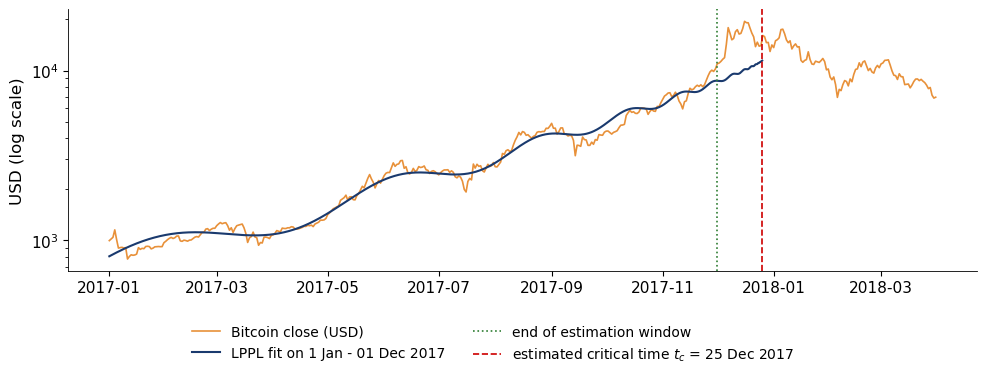

In [24]:
p_btc = daily('BTC-USD.CC', END)
T0 = pd.Timestamp('2017-01-01')


def design(t, tc, m, om):
    dt = tc - t; f = dt ** m
    return np.column_stack([np.ones_like(t), f, f * np.cos(om * np.log(dt)), f * np.sin(om * np.log(dt))])


def sse(th, t, y):
    tc, m, om = th
    if tc <= t[-1] + 1e-3 or not (0.1 <= m <= 0.9) or not (6 <= om <= 13):
        return 1e9
    X = design(t, tc, m, om); coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    return float(((y - X @ coef) ** 2).sum())


def lppl_fit(end, rng, starts):
    s_ = p_btc.loc[T0:end]
    t = ((s_.index - T0).days.values / 365.25).astype(float); y = np.log(s_.values)
    best = None
    for _ in range(starts):
        x0 = [t[-1] + rng.uniform(0.005, 0.25), rng.uniform(0.1, 0.9), rng.uniform(6, 13)]
        r_ = minimize(sse, x0, args=(t, y), method='Nelder-Mead', options={'xatol': 1e-6, 'fatol': 1e-8, 'maxiter': 4000})
        if best is None or r_.fun < best.fun:
            best = r_
    tc, m, om = best.x
    coef = np.linalg.lstsq(design(t, tc, m, om), y, rcond=None)[0]
    resid = y - design(t, tc, m, om) @ coef
    tcd = T0 + pd.Timedelta(days=tc * 365.25)
    return dict(end=pd.Timestamp(end), n=len(y), tc=tcd, lead=(tcd - pd.Timestamp(end)).days, m=m, omega=om,
                B=coef[1], C_over_B=np.hypot(coef[2], coef[3]) / abs(coef[1]),
                R2=1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum(), t=t, theta=(tc, m, om), coef=coef)


rng = np.random.default_rng(7)
fits = [lppl_fit(e, rng, 300) for e in ['2017-11-15', '2017-12-01', '2017-12-08']]
f = fits[1]
peak = p_btc.loc['2017-11-01':'2018-01-31']
print(f"Window 1 January - {f['end']:%d %B %Y}: n = {f['n']}, estimated critical time t_c = {f['tc']:%d %B %Y}, "
      f"R2 = {f['R2']:.3f}")
print(f'Actual peak: {peak.idxmax():%d %B %Y} at {peak.max():,.0f} USD; '
      f"fall to the low of 2018: {100 * (1 - p_btc.loc['2018'].min() / peak.max()):.0f}%")

tc, m, om = f['theta']
tt = np.linspace(f['t'][0], tc - 1e-4, 800)
yy = design(tt, tc, m, om) @ f['coef']
dates = [T0 + pd.Timedelta(days=x * 365.25) for x in tt]
seg = p_btc.loc['2017-01-01':'2018-03-31']
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(seg.index, seg.values, color=BTC, lw=1.2, label='Bitcoin close (USD)')
ax.plot(dates, np.exp(yy), color=BLUE, lw=1.5, label=f"LPPL fit on 1 Jan - {f['end']:%d %b %Y}")
ax.axvline(f['end'], color=GREEN, ls=':', lw=1.2, label='end of estimation window')
ax.axvline(f['tc'], color=RED, ls='--', lw=1.2, label=f"estimated critical time $t_c$ = {f['tc']:%d %b %Y}")
ax.set_yscale('log'); ax.set_ylabel('USD (log scale)')
below(fig, ncol=2, bottom=0.16)
save_fig(fig, 'ba_l2_lppl_btc2017')

### 5.5 $\hat t_c$ across estimation windows

Eleven weekly window ends, 1 October to 10 December 2017, all starting on 1 January 2017, with 120 random starts
each (random seed 11). Red circles mark fits at a parameter bound or at the window end.

window end        t_c    m  omega  at a bound
2017-10-01 2018-01-01 0.90  13.00        True
2017-10-08 2018-01-04 0.90  13.00        True
2017-10-15 2018-01-05 0.90  13.00        True
2017-10-22 2018-01-05 0.90  13.00        True
2017-10-29 2018-01-05 0.90  13.00        True
2017-11-05 2018-01-04 0.90  13.00        True
2017-11-12 2018-01-03 0.90  13.00        True
2017-11-19 2018-01-05 0.90  13.00        True
2017-11-26 2018-01-07 0.90  13.00        True
2017-12-03 2017-12-28 0.82  12.68       False
2017-12-10 2017-12-10 0.71  11.32        True

Fits at the bounds m = 0.9 and omega = 13: 9 of 11; fits with t_c at the window end: 1; interior fits: 1


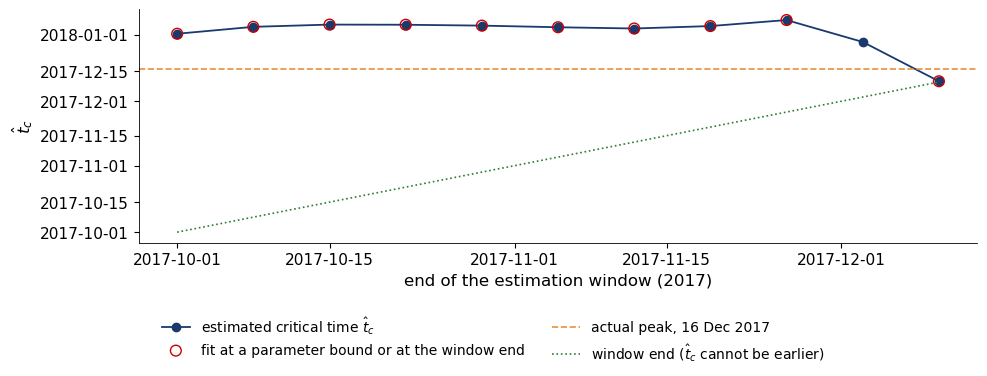

In [25]:
rng = np.random.default_rng(11)
ends = pd.date_range('2017-10-01', '2017-12-15', freq='7D')
rows = []
for e in ends:
    f_ = lppl_fit(e, rng, 120)
    tcy = f_['theta'][0]
    bound = f_['m'] > 0.89 or f_['m'] < 0.11 or f_['omega'] > 12.9 or f_['omega'] < 6.1 or tcy - f_['t'][-1] < 0.003
    rows.append({'window end': e, 't_c': f_['tc'], 'm': f_['m'], 'omega': f_['omega'], 'at a bound': bound,
                 'at m = 0.9 and omega = 13': f_['m'] > 0.89 and f_['omega'] > 12.9, 't_c at window end': tcy - f_['t'][-1] < 0.003})
W = pd.DataFrame(rows)
print(W.assign(**{'window end': W['window end'].dt.date, 't_c': W['t_c'].dt.date})[['window end', 't_c', 'm', 'omega', 'at a bound']].round(2).to_string(index=False))
print(f"\nFits at the bounds m = 0.9 and omega = 13: {int(W['at m = 0.9 and omega = 13'].sum())} of {len(W)}; "
      f"fits with t_c at the window end: {int(W['t_c at window end'].sum())}; interior fits: {int((~W['at a bound']).sum())}")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(W['window end'], W['t_c'], color=BLUE, marker='o', label=r'estimated critical time $\hat t_c$')
wb = W[W['at a bound']]
ax.scatter(wb['window end'], wb['t_c'], s=60, zorder=5, facecolors='none', edgecolors=RED,
           label='fit at a parameter bound or at the window end')
ax.axhline(peak.idxmax(), color=BTC, ls='--', lw=1.2, label=f'actual peak, {peak.idxmax():%d %b %Y}')
ax.plot(W['window end'], W['window end'], color=GREEN, ls=':', lw=1.2, label=r'window end ($\hat t_c$ cannot be earlier)')
ax.set_xlabel('end of the estimation window (2017)'); ax.set_ylabel(r'$\hat t_c$')
below(fig, ncol=2, bottom=0.18)
save_fig(fig, 'ba_l2_lppl_tc')

### 5.6 Network value: Metcalfe's law

**Metcalfe's law** says that the value of a network grows with the square of its users $n$. As a regression on logs,

$$\ln M_t = a + b \ln n_t + u_t, \qquad \text{Metcalfe: } b = 2,$$

where $M_t$ is Bitcoin's market value and $n_t$ a measure of use, here transactions per day; $b$ is an elasticity.
Data: monthly means, November 2014 to October 2025, with the 11 days of recording error found in Lecture 1 removed.
Standard errors are Newey–West with 12 lags. The **Metcalfe value** fixes $b = 2$: $\exp(\hat c + 2\ln n_t)$, with
$\hat c$ the mean of $\ln M_t - 2\ln n_t$, so that the ratio of market value to Metcalfe value is 1 on average in logs.

Two limits come first. Transactions are not users: one firm can send many transactions, and exchange users trade
off-chain. And two series with trends can give a high $R^2$ without a stable link (a spurious regression), so the
ratio is a model-dependent diagnostic, not a fair value.

Months: 132; elasticity b = 3.59 (Newey-West SE 0.43); R2 = 0.58
Test of b = 2: t = (3.59 - 2) / 0.43 = 3.66


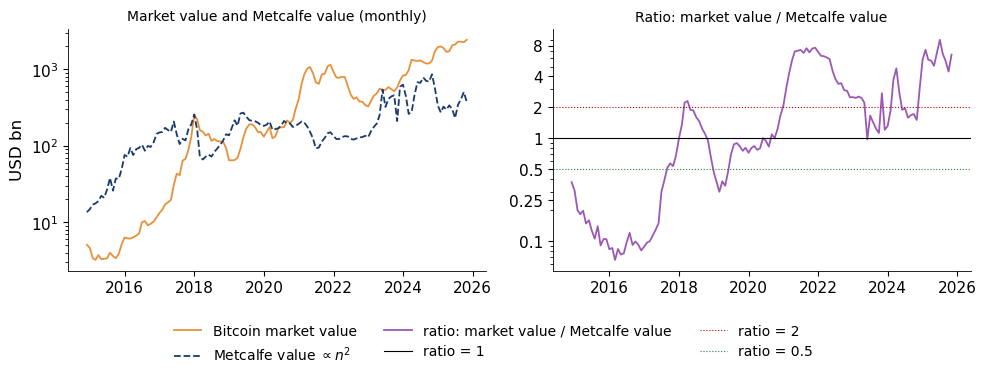

Ratio: maximum 9.1 (June 2025), minimum 0.07 (February 2016), last 6.51 (October 2025)
Share of months with ratio above 2: 36%; below 0.5: 30%


In [26]:
tx_btc = pd.to_numeric(onchain('transaction')['BTC'], errors='coerce')
mc_btc = pd.to_numeric(onchain('Mktcap')['BTC'], errors='coerce')
mc_btc.loc['2023-08-27':'2023-09-06'] = np.nan                     # recording error (Lecture 1)
mm = pd.DataFrame({'tx': tx_btc, 'mc': mc_btc}).dropna().resample('ME').mean().dropna()
y, x = np.log(mm['mc']), np.log(mm['tx'])

res = sm.OLS(y, sm.add_constant(x)).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
bhat, se = res.params.iloc[1], res.bse.iloc[1]
print(f'Months: {len(mm)}; elasticity b = {bhat:.2f} (Newey-West SE {se:.2f}); R2 = {res.rsquared:.2f}')
print(f'Test of b = 2: t = ({bhat:.2f} - 2) / {se:.2f} = {(bhat - 2) / se:.2f}')

c = (y - 2 * x).mean()
ratio = np.exp(y - (c + 2 * x))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(mm.index, mm['mc'] / 1e9, color=BTC, label='Bitcoin market value')
ax[0].plot(mm.index, np.exp(c + 2 * x) / 1e9, color=BLUE, ls='--', label=r'Metcalfe value $\propto n^2$')
ax[0].set_yscale('log'); ax[0].set_ylabel('USD bn')
ax[0].set_title('Market value and Metcalfe value (monthly)', fontsize=10)
ax[1].plot(ratio.index, ratio, color=ETH, label='ratio: market value / Metcalfe value')
ax[1].axhline(1, color='black', lw=0.8, label='ratio = 1')
ax[1].axhline(2, color=RED, lw=0.8, ls=':', label='ratio = 2'); ax[1].axhline(0.5, color=GREEN, lw=0.8, ls=':', label='ratio = 0.5')
ax[1].set_yscale('log'); ax[1].set_yticks([0.1, 0.25, 0.5, 1, 2, 4, 8]); ax[1].set_yticklabels(['0.1', '0.25', '0.5', '1', '2', '4', '8'])
ax[1].set_title('Ratio: market value / Metcalfe value', fontsize=10)
below(fig, ncol=3, bottom=0.16)
save_fig(fig, 'ba_l2_metcalfe')
print(f'Ratio: maximum {ratio.max():.1f} ({ratio.idxmax():%B %Y}), minimum {ratio.min():.2f} ({ratio.idxmin():%B %Y}), '
      f'last {ratio.iloc[-1]:.2f} ({ratio.index[-1]:%B %Y})')
print(f'Share of months with ratio above 2: {100 * (ratio > 2).mean():.0f}%; below 0.5: {100 * (ratio < 0.5).mean():.0f}%')

### 5.7 Metcalfe's law: the estimates

The regression of Section 5.6 on the full sample and on two halves, Newey–West standard errors with 12 lags. Then
three checks of the levels regression: the Engle–Granger test of cointegration (no cointegration means the levels
fit may be spurious), the same regression with a linear time trend, and the regression of monthly changes
$\Delta\ln M_t$ on $\Delta\ln n_t$ (Newey–West, 3 lags).

In [27]:
rows = {}
for lab, (a, bnd) in {'2014-2025': ('2014', '2025'), '2014-2019': ('2014', '2019'), '2020-2025': ('2020', '2025')}.items():
    s_ = mm.loc[a:bnd]
    r_ = sm.OLS(np.log(s_['mc']), sm.add_constant(np.log(s_['tx']))).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
    rows[lab] = {'months': len(s_), 'b': r_.params.iloc[1], 'standard error': r_.bse.iloc[1], 'R2': r_.rsquared,
                 't for b = 2': (r_.params.iloc[1] - 2) / r_.bse.iloc[1]}
tt_ = np.arange(len(mm))
r_t = sm.OLS(y, sm.add_constant(np.column_stack([x, tt_]))).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
rows['2014-2025, with a linear time trend'] = {'months': len(mm), 'b': r_t.params.iloc[1], 'standard error': r_t.bse.iloc[1],
                                               'R2': r_t.rsquared, 't for b = 2': (r_t.params.iloc[1] - 2) / r_t.bse.iloc[1]}
dd_ = pd.DataFrame({'dy': y.diff(), 'dx': x.diff()}).dropna()
r_d = sm.OLS(dd_['dy'], sm.add_constant(dd_['dx'])).fit(cov_type='HAC', cov_kwds={'maxlags': 3})
rows['2014-2025, monthly changes'] = {'months': len(dd_), 'b': r_d.params.iloc[1], 'standard error': r_d.bse.iloc[1],
                                      'R2': r_d.rsquared, 't for b = 2': (r_d.params.iloc[1] - 2) / r_d.bse.iloc[1]}
MT = pd.DataFrame(rows).T; MT['months'] = MT['months'].astype(int)
print(MT.round(2).to_string())
from statsmodels.tsa.stattools import coint
print(f'\nEngle-Granger cointegration test of ln M and ln n: p-value {coint(y, x)[1]:.2f}')

                                     months     b  standard error    R2  t for b = 2
2014-2025                               132  3.59            0.43  0.58         3.66
2014-2019                                62  2.71            0.35  0.52         2.02
2020-2025                                70  1.17            0.48  0.20        -1.72
2014-2025, with a linear time trend     132  0.27            0.47  0.89        -3.69
2014-2025, monthly changes              131  0.31            0.15  0.05       -11.11

Engle-Granger cointegration test of ln M and ln n: p-value 0.57


### 5.8 Metcalfe's law in levels and in changes

The regression of Section 5.6 drawn twice: log levels with the fitted slope and Metcalfe's slope of 2 (through the
means), and monthly log changes with their fitted slope. Newey–West standard errors with 12 lags in levels and 3 in
changes, as in Section 5.7.

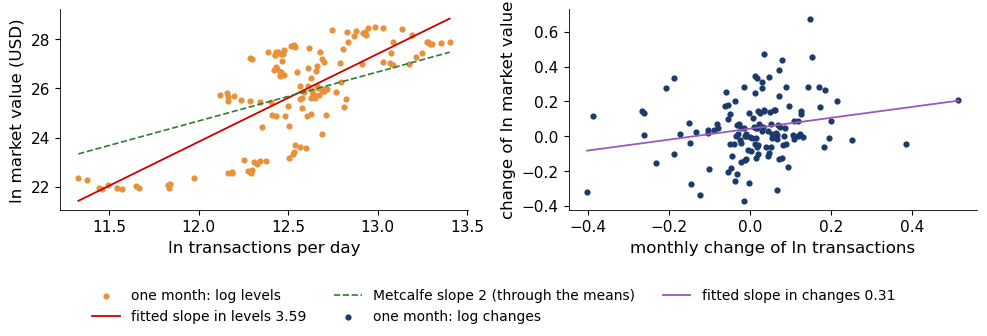

Levels: 132 months, b = 3.59 (SE 0.43), R2 = 0.58
Changes: 131 months, b = 0.31 (SE 0.15), R2 = 0.05
Standard deviation of the monthly changes: ln transactions 0.123, ln market value 0.174
Correlation of the monthly changes: 0.22


In [28]:
# Metcalfe's law: log levels against monthly log changes, Bitcoin, November 2014 - October 2025
tx_m = pd.to_numeric(onchain('transaction')['BTC'], errors='coerce')
mc_m = pd.to_numeric(onchain('Mktcap')['BTC'], errors='coerce')
mc_m.loc['2023-08-27':'2023-09-06'] = np.nan                      # recording error (Lecture 1)
mon = pd.DataFrame({'tx': tx_m, 'mc': mc_m}).dropna().resample('ME').mean().dropna()
ly, lx = np.log(mon['mc']), np.log(mon['tx'])
fit_l = sm.OLS(ly, sm.add_constant(lx)).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
dly, dlx = ly.diff().dropna(), lx.diff().dropna()
fit_d = sm.OLS(dly, sm.add_constant(dlx)).fit(cov_type='HAC', cov_kwds={'maxlags': 3})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].scatter(lx, ly, color=BTC, s=12, label='one month: log levels')
xs = np.linspace(lx.min(), lx.max(), 50)
ax[0].plot(xs, fit_l.params.iloc[0] + fit_l.params.iloc[1] * xs, color=RED, lw=1.3, label=f'fitted slope in levels {fit_l.params.iloc[1]:.2f}')
ax[0].plot(xs, ly.mean() + 2 * (xs - lx.mean()), color=GREEN, ls='--', lw=1.2, label='Metcalfe slope 2 (through the means)')
ax[0].set_xlabel('ln transactions per day'); ax[0].set_ylabel('ln market value (USD)')
ax[1].scatter(dlx, dly, color=BLUE, s=12, label='one month: log changes')
xd = np.linspace(dlx.min(), dlx.max(), 50)
ax[1].plot(xd, fit_d.params.iloc[0] + fit_d.params.iloc[1] * xd, color=ETH, lw=1.3, label=f'fitted slope in changes {fit_d.params.iloc[1]:.2f}')
ax[1].set_xlabel('monthly change of ln transactions'); ax[1].set_ylabel('change of ln market value')
legend_below(fig, ncol=3, bottom=0.18)
save_fig(fig, 'ba_l2_metcalfe_changes')
print(f'Levels: {len(mon)} months, b = {fit_l.params.iloc[1]:.2f} (SE {fit_l.bse.iloc[1]:.2f}), R2 = {fit_l.rsquared:.2f}')
print(f'Changes: {len(dly)} months, b = {fit_d.params.iloc[1]:.2f} (SE {fit_d.bse.iloc[1]:.2f}), R2 = {fit_d.rsquared:.2f}')
print(f'Standard deviation of the monthly changes: ln transactions {dlx.std():.3f}, ln market value {dly.std():.3f}')
print(f'Correlation of the monthly changes: {np.corrcoef(dlx, dly)[0, 1]:.2f}')

## Appendix: Further Material

### A.1 The tail index and the Hill estimator

Far in the tail, losses $L = -r$ follow a power law, $P(L > x) \approx c\,x^{-\alpha}$; $\alpha$ is the **tail index**.
A smaller $\alpha$ means a heavier tail, and moments of order $q \ge \alpha$ are infinite: $\alpha < 4$ means infinite
kurtosis. The Hill estimator uses the $k$ largest losses $L_{(1)} \ge \dots \ge L_{(k+1)}$, with a 95% confidence
interval (CI):

$$\hat\alpha = \Bigg[\frac1k\sum_{i=1}^{k} \ln\frac{L_{(i)}}{L_{(k+1)}}\Bigg]^{-1}, \qquad \mathrm{CI}_{95\%} = \hat\alpha\Big(1 \pm \frac{1.96}{\sqrt k}\Big).$$

The table uses $k = 2.5\%$ of the number of returns $n$, losses for the left tail and gains for the right tail, on
the full history of each asset (since 2014; Ethereum since 2016) to 18 September 2026.

In [29]:
def hill(xx, k):
    xx = np.sort(np.asarray(xx, float))[::-1]
    return 1.0 / np.mean(np.log(xx[:k] / xx[k]))


rows = {}
for k_ in ['btc', 'eth', 'sp500', 'gold']:
    x_ = returns(k_).values; kk = int(0.025 * len(x_))
    al, ar = hill(-x_[x_ < 0], kk), hill(x_[x_ > 0], kk)
    h = 1.96 / np.sqrt(kk)
    rows[NAME[k_]] = {'n': len(x_), 'k': kk, 'left tail alpha': al, 'CI low': al * (1 - h), 'CI high': al * (1 + h),
                      'right tail alpha': ar, 'CI low ': ar * (1 - h), 'CI high ': ar * (1 + h)}
HT = pd.DataFrame(rows).T; HT[['n', 'k']] = HT[['n', 'k']].astype(int)
print(HT.round(2).to_string())

             n    k  left tail alpha  CI low  CI high  right tail alpha  CI low   CI high 
Bitcoin   4384  109             2.71    2.20     3.21              3.37     2.74      4.00
Ethereum  3913   97             2.62    2.10     3.15              3.09     2.48      3.71
S&P 500   3017   75             2.68    2.08     3.29              2.80     2.17      3.43
Gold      3124   78             3.11    2.42     3.80              3.04     2.36      3.71


### A.2 Tail plot and Hill plot

Left: the empirical probability that the standardised loss exceeds $x$, on log-log scales; a power-law tail is a
straight line with slope $-\alpha$, while the Normal (red) bends down. Right: the Hill estimate (all daily returns
sorted by loss) against $k$, as a percentage of $n$, with 95% bands; 2018–2026. A small $k$ uses few observations
(wide bands); a large $k$ lets the centre of the distribution bias $\hat\alpha$ downwards.

Bitcoin Hill estimates: 4.33 (k = 1%), 2.71 (k = 2.5%), 2.60 (k = 5%), 1.94 (k = 10%)
S&P 500 Hill estimates: 2.92 (k = 1%), 2.81 (k = 2.5%), 2.32 (k = 5%), 1.94 (k = 10%)


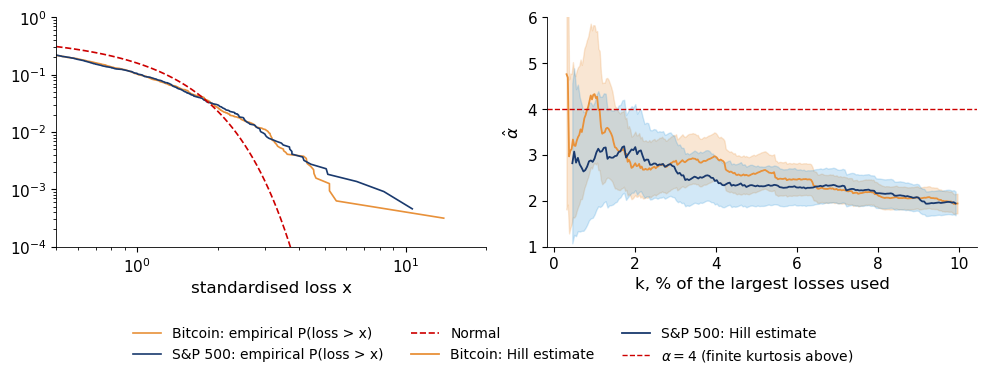

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
xs = np.logspace(np.log10(0.5), np.log10(15), 100)
for k_, col in [('Bitcoin', BTC), ('S&P 500', BLUE)]:
    r_ = R[k_]; L = np.sort(-(r_ - r_.mean()) / r_.std())[::-1]; L = L[L > 0]
    ax[0].loglog(L, np.arange(1, len(L) + 1) / len(r_), color=col, lw=1.2, label=f'{k_}: empirical P(loss > x)')
ax[0].loglog(xs, stats.norm.sf(xs), color=RED, ls='--', lw=1.2, label='Normal')
ax[0].set_xlabel('standardised loss x'); ax[0].set_ylim(1e-4, 1); ax[0].set_xlim(0.5, 20)
band_col = {'Bitcoin': BTC, 'S&P 500': '#3498DB'}
for k_, col in [('Bitcoin', BTC), ('S&P 500', BLUE)]:
    r_ = R[k_]; L = np.sort(-r_.values)[::-1]; n_ = len(r_)
    ks = np.arange(10, int(0.10 * n_))
    a_ = np.array([1 / np.mean(np.log(L[:kk] / L[kk])) for kk in ks])
    ax[1].plot(ks / n_ * 100, a_, color=col, label=f'{k_}: Hill estimate')
    ax[1].fill_between(ks / n_ * 100, a_ * (1 - 1.96 / np.sqrt(ks)), a_ * (1 + 1.96 / np.sqrt(ks)), color=band_col[k_], alpha=0.22)
    msg = ', '.join(f'{a_[np.argmin(abs(ks - pc / 100 * n_))]:.2f} (k = {pc}%)' for pc in [1, 2.5, 5, 10])
    print(f'{k_} Hill estimates: {msg}')
ax[1].axhline(4, color=RED, ls='--', lw=1, label=r'$\alpha = 4$ (finite kurtosis above)')
ax[1].set_xlabel('k, % of the largest losses used'); ax[1].set_ylabel(r'$\hat\alpha$'); ax[1].set_ylim(1, 6)
below(fig, ncol=3, bottom=0.16)
save_fig(fig, 'ba_l2_tails')

### A.3 Stability of kurtosis over time

Skewness and excess kurtosis of Bitcoin's daily returns on rolling 365-day windows, 2018–2026.

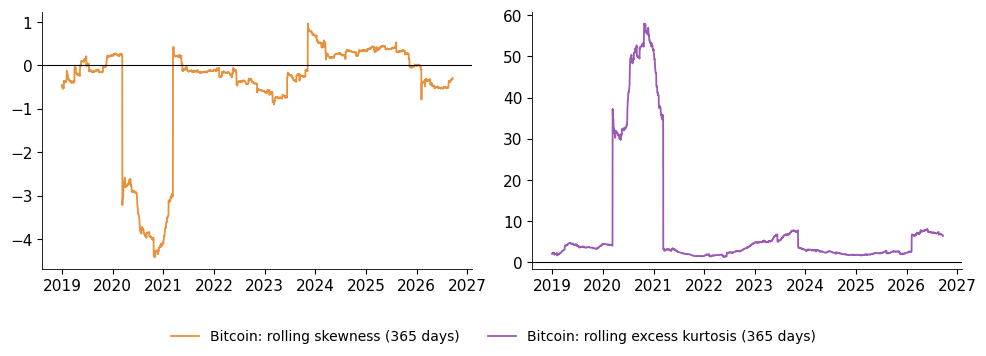

Rolling excess kurtosis: minimum 1.3, maximum 58.0 (window ending 26 October 2020), last 6.4
Rolling skewness: minimum -4.41, maximum 0.96, last -0.29


In [31]:
rs, rk = b.rolling(365).skew(), b.rolling(365).kurt()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(rs.index, rs, color=BTC, label='Bitcoin: rolling skewness (365 days)'); ax[0].axhline(0, color='black', lw=0.8)
ax[1].plot(rk.index, rk, color=ETH, label='Bitcoin: rolling excess kurtosis (365 days)'); ax[1].axhline(0, color='black', lw=0.8)
below(fig, ncol=2, bottom=0.12)
save_fig(fig, 'ba_l2_rolling_moments')
print(f'Rolling excess kurtosis: minimum {rk.min():.1f}, maximum {rk.max():.1f} (window ending {rk.idxmax():%d %B %Y}), '
      f'last {rk.iloc[-1]:.1f}')
print(f'Rolling skewness: minimum {rs.min():.2f}, maximum {rs.max():.2f}, last {rs.iloc[-1]:.2f}')

### A.4 Weekday and weekend volatility of Bitcoin

Standard deviation of Bitcoin's daily returns by the day of the closing price, in three periods. The weekend
variance ratio is the variance of Saturday and Sunday returns divided by the variance of weekday returns; the mean
weekend effect is the coefficient $b$ of $r_t = a + b\,W_t + e_t$, where $W_t$ is 1 on weekends, with Newey–West
standard errors (10 lags).

2014-2019: weekend / weekday variance = 0.66; weekend effect on the mean b = -0.011 (t = -0.07)
2020-2023: weekend / weekday variance = 0.35; weekend effect on the mean b = -0.111 (t = -0.71)
2024-2026: weekend / weekday variance = 0.39; weekend effect on the mean b = -0.032 (t = -0.21)


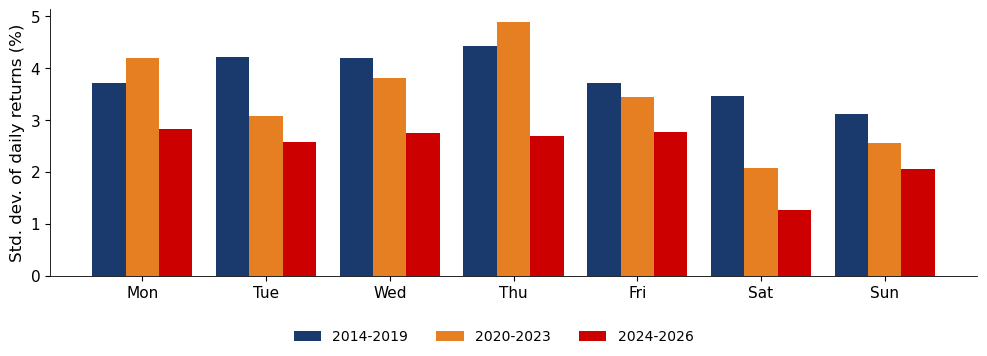

In [32]:
DAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
PERIODS = {'2014-2019': ('2014-09-17', '2019-12-31'), '2020-2023': ('2020-01-01', '2023-12-31'), '2024-2026': ('2024-01-01', END)}
fig, ax = plt.subplots(figsize=(10, 3.6))
xd = np.arange(7)
for i, ((lab, (a, bnd)), col) in enumerate(zip(PERIODS.items(), [BLUE, ORANGE, RED])):
    r_ = returns('btc', a, bnd)
    d = pd.DataFrame({'r': r_, 'dow': r_.index.dayofweek})
    ax.bar(xd + (i - 1) * 0.27, d.groupby('dow')['r'].std().values, width=0.27, color=col, label=lab)
    we = (d['dow'] >= 5).astype(float)
    reg = sm.OLS(d['r'], sm.add_constant(we)).fit(cov_type='HAC', cov_kwds={'maxlags': 10})
    print(f'{lab}: weekend / weekday variance = {d.loc[we == 1, "r"].var() / d.loc[we == 0, "r"].var():.2f}; '
          f'weekend effect on the mean b = {reg.params.iloc[1]:.3f} (t = {reg.tvalues.iloc[1]:.2f})')
ax.set_xticks(xd); ax.set_xticklabels(DAYS); ax.set_ylabel('Std. dev. of daily returns (%)')
below(fig, ncol=3, bottom=0.10)
save_fig(fig, 'ba_l2_weekday')

### A.5 Three crisis episodes

Cumulative log return, in log-return percentage points, from the close of the first day to the close of the last day
of each episode, and the corresponding simple return $e^{r/100} - 1$ (the share of the value lost or gained).

In [33]:
EPIS = {'COVID-19': ('2020-02-19', '2020-03-23'), 'Terra/Luna': ('2022-05-05', '2022-05-12'), 'FTX': ('2022-11-05', '2022-11-21')}
rows = {}
for lab, (a, bnd) in EPIS.items():
    row = {'period': f'{a} to {bnd}'}
    for k_ in ['btc', 'eth', 'sp500', 'gold']:
        p_ = close(k_, '2014-01-01')
        lr_ = np.log(p_.loc[:bnd].iloc[-1] / p_.loc[:a].iloc[-1])
        row[NAME[k_] + ' log (%)'] = round(100 * lr_, 1)
        row[NAME[k_] + ' simple (%)'] = round(100 * (np.exp(lr_) - 1), 1)
    rows[lab] = row
print(pd.DataFrame(rows).T.to_string())

                              period Bitcoin log (%) Bitcoin simple (%) Ethereum log (%) Ethereum simple (%) S&P 500 log (%) S&P 500 simple (%) Gold log (%) Gold simple (%)
COVID-19    2020-02-19 to 2020-03-23           -40.6              -33.4            -65.5               -48.1           -41.4              -33.9          0.3             0.3
Terra/Luna  2022-05-05 to 2022-05-12           -23.0              -20.6            -33.8               -28.6            -5.4               -5.2         -3.0            -2.9
FTX         2022-11-05 to 2022-11-21           -29.9              -25.8            -38.4               -31.9             4.6                4.8          3.4             3.4


### A.6 Bitcoin as a hedge, safe haven or risk asset

Baur and Lucey (2010) call an asset a **hedge** if it is uncorrelated or negatively correlated with equities on
average, and a **safe haven** if it is uncorrelated or negatively correlated with equities in extreme market stress.
The check below is simpler: the set $\mathcal{S}$ of the worst 5% of S&P 500 days and the mean return of asset $x$
on those days, with a 95% confidence interval. Not rejecting a zero mean does not show that the mean is
non-negative.

$$\bar x_{\mathcal{S}} = \frac{1}{n_{\mathcal{S}}}\sum_{t \in \mathcal{S}} x_t, \qquad t = \frac{\bar x_{\mathcal{S}}}{s_{\mathcal{S}}/\sqrt{n_{\mathcal{S}}}}.$$

Days common to all four assets, 2018–2026; the chart shows 95% confidence intervals.

Worst 5% of S&P 500 days: 110 days with a return below -1.77%
          mean on worst days (%)  95% CI low  95% CI high  95% CI half-width       t  mean on all days (%)
S&P 500                   -2.958      -3.251       -2.666              0.292 -19.825                 0.048
Bitcoin                   -3.357      -4.723       -1.992              1.366  -4.818                 0.078
Ethereum                  -4.995      -6.683       -3.306              1.688  -5.798                 0.057
Gold                       0.012      -0.268        0.293              0.281   0.085                 0.055


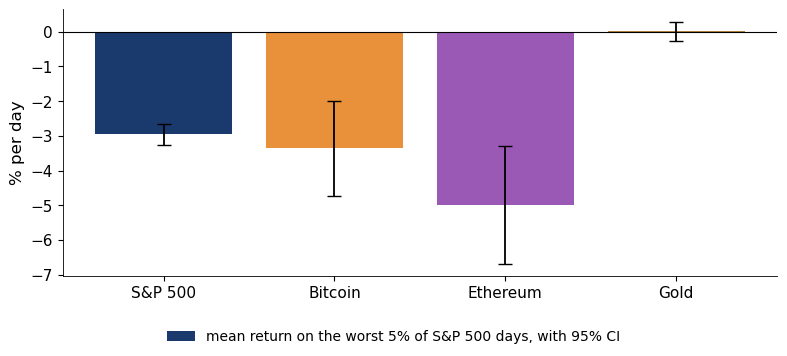

In [34]:
px = pd.concat({NAME[k_]: close_all(SYM[k_]) for k_ in ['sp500', 'btc', 'eth', 'gold']}, axis=1).dropna()
X = (100 * np.log(px).diff()).dropna().loc['2018-01-01':]
thr = X['S&P 500'].quantile(0.05)
Sd = X[X['S&P 500'] <= thr]
print(f'Worst 5% of S&P 500 days: {len(Sd)} days with a return below {thr:.2f}%')
rows = {}
for k_ in ['S&P 500', 'Bitcoin', 'Ethereum', 'Gold']:
    m_, s_ = Sd[k_].mean(), Sd[k_].std()
    rows[k_] = {'mean on worst days (%)': m_, '95% CI low': m_ - 1.96 * s_ / np.sqrt(len(Sd)),
                '95% CI high': m_ + 1.96 * s_ / np.sqrt(len(Sd)), '95% CI half-width': 1.96 * s_ / np.sqrt(len(Sd)),
                't': m_ / (s_ / np.sqrt(len(Sd))), 'mean on all days (%)': X[k_].mean()}
SH = pd.DataFrame(rows).T
print(SH.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(SH.index, SH['mean on worst days (%)'], yerr=SH['95% CI half-width'], color=[BLUE, BTC, ETH, GOLD], capsize=5,
       label='mean return on the worst 5% of S&P 500 days, with 95% CI')
ax.axhline(0, color='black', lw=0.8); ax.set_ylabel('% per day')
below(fig, ncol=1, bottom=0.10)
save_fig(fig, 'ba_l2_safe_haven')

### A.7 LPPL estimates: stability of $\hat t_c$

The three windows of Section 5.4. The lead is the number of days from the end of the window to $\hat t_c$. Fits at
the bounds of the search ($m = 0.9$, $\omega = 13$) or with $\hat t_c$ at the last observation are poorly identified.

In [35]:
tab = pd.DataFrame([{'window ends': f_['end'].date(), 'n': f_['n'], 't_c': f_['tc'].date(), 'lead (days)': f_['lead'],
                     'm': f_['m'], 'omega': f_['omega'], 'B': f_['B'], '|C|/|B|': f_['C_over_B'], 'R2': f_['R2']}
                    for f_ in fits]).set_index('window ends')
print(tab.round(3).to_string())

               n         t_c  lead (days)      m   omega      B  |C|/|B|     R2
window ends                                                                    
2017-11-15   319  2018-01-04           50  0.900  13.000 -2.759    0.089  0.980
2017-12-01   335  2017-12-25           24  0.851  12.492 -2.837    0.088  0.982
2017-12-08   342  2017-12-08            0  0.741  11.144 -2.898    0.081  0.979


### A.8 A rolling Metcalfe elasticity

$\hat b$ on rolling 36-month windows with Newey–West (6 lags) 95% intervals; red: Metcalfe's $b = 2$.

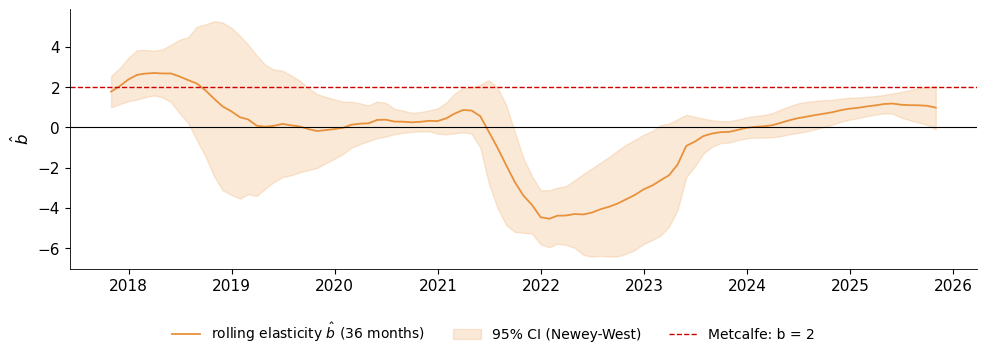

First window (October 2017): b = 1.78; maximum 2.70 (window ending March 2018); last (October 2025): 0.98
Share of windows whose interval covers 2: 28%


In [36]:
bs, ses, dts = [], [], []
for i in range(36, len(mm) + 1):
    s_ = mm.iloc[i - 36:i]
    r_ = sm.OLS(np.log(s_['mc']), sm.add_constant(np.log(s_['tx']))).fit(cov_type='HAC', cov_kwds={'maxlags': 6})
    bs.append(r_.params.iloc[1]); ses.append(r_.bse.iloc[1]); dts.append(s_.index[-1])
bs, ses = np.array(bs), np.array(ses)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(dts, bs, color=BTC, label=r'rolling elasticity $\hat b$ (36 months)')
ax.fill_between(dts, bs - 1.96 * ses, bs + 1.96 * ses, color=BTC, alpha=0.2, label='95% CI (Newey-West)')
ax.axhline(2, color=RED, ls='--', lw=1, label='Metcalfe: b = 2'); ax.axhline(0, color='black', lw=0.8)
ax.set_ylabel(r'$\hat b$')
below(fig, ncol=3, bottom=0.12)
save_fig(fig, 'ba_l2_metcalfe_rolling')
print(f'First window ({dts[0]:%B %Y}): b = {bs[0]:.2f}; maximum {bs.max():.2f} (window ending {dts[int(bs.argmax())]:%B %Y}); '
      f'last ({dts[-1]:%B %Y}): {bs[-1]:.2f}')
print(f'Share of windows whose interval covers 2: {100 * np.mean((bs - 1.96 * ses <= 2) & (bs + 1.96 * ses >= 2)):.0f}%')

### A.9 Variance ratio from autocorrelations

$\mathrm{VR}(q) \approx 1 + 2\sum_{j=1}^{q-1}\big(1 - \frac{j}{q}\big)\rho(j)$; for $q = 2$, $\mathrm{VR}(2) \approx 1 + \rho(1)$.
Whole samples since 2014.

In [37]:
for k_ in ['btc', 'sp500']:
    x_ = returns(k_).values; rho1 = acf(x_, 1)[0]
    print(f'{NAME[k_]}: rho(1) = {rho1:.3f}, so VR(2) is about {1 + rho1:.3f}; direct estimate {variance_ratio(x_, 2)[0]:.3f}')

Bitcoin: rho(1) = -0.022, so VR(2) is about 0.978; direct estimate 0.977
S&P 500: rho(1) = -0.126, so VR(2) is about 0.874; direct estimate 0.875


### A.10 The variance-ratio profile

$\widehat{\mathrm{VR}}(q)$ for $q = 2, \dots, 30$ days on the 2018–2026 returns (every close in the file); shaded: the
robust 95% band for Bitcoin, $1 \pm 1.96\sqrt{\hat\theta^*(q)}$. The profile uses the sum of the last $q$ returns
on every day.

Bitcoin: VR(5) = 0.989 (Z* = -0.19); VR(20) = 1.077 (Z* = 0.66)
Ethereum: VR(5) = 1.001 (Z* = 0.03); VR(20) = 1.110 (Z* = 0.95)
S&P 500: VR(5) = 0.836 (Z* = -1.21); VR(20) = 0.796 (Z* = -0.76)


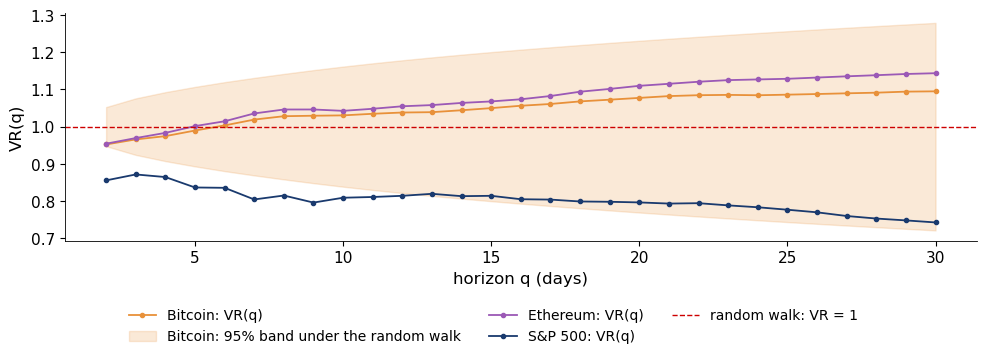

In [38]:
def vr_profile(r_, q):
    x_ = r_.values; n_ = len(x_); mu = x_.mean(); e = x_ - mu
    s1 = (e ** 2).sum() / n_
    rq = pd.Series(x_).rolling(q).sum().dropna().values
    vr = ((rq - q * mu) ** 2).sum() / (n_ * q) / s1
    den = ((e ** 2).sum()) ** 2
    theta = sum((2 * (q - j) / q) ** 2 * (e[j:] ** 2 * e[:-j] ** 2).sum() / den * n_ for j in range(1, q))
    return vr, np.sqrt(theta / n_)


qs = np.arange(2, 31)
fig, ax = plt.subplots(figsize=(10, 3.6))
for k_, col in [('Bitcoin', BTC), ('Ethereum', ETH), ('S&P 500', BLUE)]:
    out = np.array([vr_profile(R[k_], q) for q in qs])
    ax.plot(qs, out[:, 0], color=col, marker='o', ms=3, label=f'{k_}: VR(q)')
    if k_ == 'Bitcoin':
        ax.fill_between(qs, 1 - 1.96 * out[:, 1], 1 + 1.96 * out[:, 1], color=BTC, alpha=0.2,
                        label='Bitcoin: 95% band under the random walk')
    print(f'{k_}: VR(5) = {out[3, 0]:.3f} (Z* = {(out[3, 0] - 1) / out[3, 1]:.2f}); '
          f'VR(20) = {out[18, 0]:.3f} (Z* = {(out[18, 0] - 1) / out[18, 1]:.2f})')
ax.axhline(1, color=RED, ls='--', lw=1, label='random walk: VR = 1')
ax.set_xlabel('horizon q (days)'); ax.set_ylabel('VR(q)')
below(fig, ncol=3, bottom=0.14)
save_fig(fig, 'ba_l2_vr_profile')

### A.11 Bitcoin's large drawdowns

Episodes between two record highs whose deepest drawdown is below −50%, since 17 September 2014: the peak, the
trough, the depth, the day of the next record and the days under water (peak to new record).

In [39]:
pb = close('btc')
ddb = (pb / pb.cummax() - 1) * 100
vals, idx = ddb.values, ddb.index
eps, i = [], 0
while i < len(vals):
    if vals[i] < 0:
        j = i
        while j < len(vals) and vals[j] < 0:
            j += 1
        seg_ = ddb.iloc[i:j]
        if seg_.min() <= -50:
            pk_ = idx[max(i - 1, 0)]; tr_ = seg_.idxmin()
            eps.append({'peak': pk_.date(), 'peak (USD)': pb[pk_], 'trough': tr_.date(), 'trough (USD)': pb[tr_],
                        'depth (%)': seg_.min(), 'new record': idx[j].date() if j < len(vals) else 'not yet',
                        'days under water': (idx[j] - pk_).days if j < len(vals) else None})
        i = j
    else:
        i += 1
print(pd.DataFrame(eps).round(1).to_string(index=False))

      peak  peak (USD)     trough  trough (USD)  depth (%) new record  days under water
2014-09-17       457.3 2015-01-14         178.1      -61.1 2015-12-15             454.0
2017-12-16     19497.4 2018-12-15        3236.8      -83.4 2020-11-30            1080.0
2021-04-13     63503.5 2021-07-20       29807.3      -53.1 2021-10-19             189.0
2021-11-08     67566.8 2022-11-21       15787.3      -76.6 2024-03-04             847.0
2025-10-06    124752.5 2026-06-30       58558.9      -53.1    not yet               NaN


### A.12 Accelerating oscillations

The peaks $t_k$ of the cosine term satisfy $\omega\ln(t_c - t_k) - \phi = 2\pi k$, so consecutive distances to $t_c$
shrink by a constant factor, $(t_c - t_{k+1})/(t_c - t_k) = e^{-2\pi/\omega}$. The cell uses $\hat\omega$ of the
1 December 2017 fit.

In [40]:
om_hat = fits[1]['omega']
fac = np.exp(-2 * np.pi / om_hat)
print(f'omega = {om_hat:.2f}; shrink factor exp(-2 pi / omega) = {fac:.3f}; scaling ratio exp(2 pi / omega) = {1 / fac:.2f}')
print('Days before t_c of consecutive peaks, starting 30 days before:', ', '.join(f'{30 * fac ** i:.1f}' for i in range(4)))

omega = 12.49; shrink factor exp(-2 pi / omega) = 0.605; scaling ratio exp(2 pi / omega) = 1.65
Days before t_c of consecutive peaks, starting 30 days before: 30.0, 18.1, 11.0, 6.6
